# Visualisations of 4-D Marine Heatwave Events in the Northeast Pacific (GLORYS12)

This notebook plots the events tracked by [`02_track_extremes_4d.ipynb`](02_track_extremes_4d.ipynb), on the anomalies
written by [`01_preprocess_extremes.ipynb`](01_preprocess_extremes.ipynb). The events are volumes that evolve in
time, so the figures show how deep an event reaches, how much excess heat it contains, and how much of it is hidden
from the surface.

The notebook follows two heatwaves. Both are in the northeast Pacific in 2015, during the marine heatwave known as the
Blob (Bond et al., 2015), and they touch. The deep heatwave has a peak volume of 0.29 × 10¹⁵ m³ and
0.38 ZJ of excess heat. The surface heatwave is a warm layer at the surface, with 0.16 × 10¹⁵ m³ and 1.08 ZJ. Each is found from a
point inside it on one day, because event IDs are labels and can change between runs. The notebook's own figures draw the deep heatwave
in blue and the surface heatwave in orange.

The figures draw each event as an isosurface with `scipy` and `scikit-image`, which marEx already depends on, and
`matplotlib`. They need no graphics card or display, so they render on a compute node.

Compute: one compute node, with a local cluster of 16 single-threaded workers × 14 GB.

## Setup

In [1]:
import shutil
import subprocess
from getpass import getuser
from pathlib import Path

import dask
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Video
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, PowerNorm, TwoSlopeNorm, to_rgb
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import proj3d
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.ndimage import distance_transform_edt, gaussian_filter
from skimage.measure import find_contours, marching_cubes

import marEx
import marEx.helper as hpc
from marEx.plotX import PlotConfig, animate_event_levels, plot_event_depth_time, plot_event_levels, plot_event_summary

2026-11-05 15:02:31 - marEx - INFO - [PID:479753] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()
out_dir = scratch_dir / "marEx" / "examples" / "4d"  # where notebooks 01 and 02 wrote their output
plot_dir = out_dir / "plots"

# The two events drawn throughout, each named by a point inside it on one day
main_point = {"time": "2015-08-10", "lat": 44.2, "lon": -135.2, "depth": 750.0}
surface_point = {"time": "2015-08-10", "lat": 46.2, "lon": -131.4, "depth": 30.0}

movie_every = 3  # days between movie frames
margin = 2.0  # degrees of padding around the events in the 3-D box and the maps

# One compute node: 16 single-threaded workers x 14 GB = 224 GB. Movie frames render one per task without threads.
n_workers, threads_per_worker, memory_limit = 16, 1, "14GB"

In [3]:
plot_dir.mkdir(parents=True, exist_ok=True)

# memory_limit is set explicitly so the workers stay within the job's allocation (Dask otherwise sizes them from
# the whole node's memory).
client = hpc.start_local_cluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    memory_limit=memory_limit,
    scratch_dir=scratch_dir / "marEx" / "dask",
)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-11-05 15:02:43 - marEx.helper.cluster - INFO - [PID:479753] - Starting local Dask cluster with 16 workers, 1 threads each


2026-11-05 15:02:43 - marEx.helper.dask_config - INFO - [PID:479753] - Configuring Dask for HPC environment


2026-11-05 15:02:43 - marEx.helper.dask_config - INFO - [PID:479753] - Using scratch directory: /scratch/<u>/<user>/marEx/dask


2026-11-05 15:02:43 - marEx.helper.dask_config - INFO - [PID:479753] - Dask temporary directory: /scratch/<u>/<user>/marEx/dask/tmp8r5fp93m


2026-11-05 15:02:43 - marEx.helper.dask_config - INFO - [PID:479753] - Dask configuration completed


2026-11-05 15:02:43 - marEx.helper.cluster - INFO - [PID:479753] - System resources: 128 physical cores, 256 logical cores, 251.6GB total memory


... (3 outputs left out)

Hostname: <node>
Forward Port: <node>:8787
Dashboard Link: localhost:8787/status
2026-11-05 15:02:49 - marEx.helper.cluster - INFO - [PID:479753] - Local cluster started successfully - Dashboard: http://127.0.0.1:8787/status


2026-11-05 15:02:49 - marEx.helper.cluster - INFO - [PID:479753] - After cluster startup - Memory Usage - RSS: 574.3MB, Virtual: 27292.0MB, Percent: 0.2%, Available: 244981.1MB


2026-11-05 15:02:49 - marEx.helper.resources - INFO - [PID:479753] - Cluster: 16 workers, 16 threads, memory_limit per worker [14.0] GB (224 GB total)


<env>/lib/python3.10/contextlib.py:142: UserWarning: Creating scratch directories is taking a surprisingly long time. (3.76s) This is often due to running workers on a network file system. Consider specifying a local-directory to point workers to write scratch data to a local disk.
  next(self.gen)


The look of every figure is set here, once: a white background, one colour per event, a ramp for each event's
anomaly, and a colour for depth. `set_look` switches to a dark slate look, which the poster image and the two films
below use.

In [4]:
# One look for every figure, set here once. The notebook's figures are light, for the page; the poster image and the
# films written for the README are dark. `set_look` picks one: it reassigns the colour names below and the Matplotlib
# defaults, and every figure function reads those names when it draws. Each event keeps one hue in both looks:
# blue for the deep heatwave, orange for the surface heatwave.
LOOKS = {
    "dark": dict(
        INK="#dbe4ee",
        MUTED="#9fb0c3",
        GRID="#2f3f54",
        FRAME="#2f3f54",
        FIGURE_BG="#111925",
        AXES_BG="#182231",
        OCEAN="#2b3a4d",
        LAND="#0d131c",
        COAST="#8da0b5",
        BOX_COLOUR="white",
        NEUTRAL="#cfd8e3",  # map ocean, land, coast; the domain box on the globe; other heatwaves' outlines
        MAIN_COLOUR="#3dd0f5",
        SURFACE_COLOUR="#ff9b3d",
        OTHER_COLOUR="#8fa3bd",
        FLOOR_RGB=(0.085, 0.12, 0.18),
        LAND_RGB=(0.05, 0.075, 0.11),  # the floor and the land of the 3-D box
        SHADE=(0.45, 0.65, 0.25),  # the isosurface lighting: ambient, diffuse and specular weights
        WARMER="lighter",
        MAIN_CMAP=["#0b2231", "#0e6a8c", "#3dd0f5", "#eafcff"],
        SURFACE_CMAP=["#2b1407", "#a63f0b", "#ff9b3d", "#fff4d6"],
        PLATE_CMAP=["#1d2b3f", "#34506f", "#6a7596", "#b08aa0", "#f4cfa4"],
        DIVERGING=["#4aa3df", "#2a4766", "#1f2b3b", "#6a7596", "#b08aa0", "#f4cfa4"],  # cool, zero, warm
        FOOTPRINT_CMAP=[
            "#5a9ab5",
            "#6f93d6",
            "#9a7bf0",
            "#f6c1ff",
        ],  # lightness never falls with depth, every stop clears the ocean
        HEAT_CMAP=["#6f4a7a", "#b5647f", "#e89a86", "#fbd9a3"],  # degrees above normal, where a threshold is passed
        QUIET_CMAP=["#1b2736", "#34465c"],  # below the threshold: faint, with the structure kept
        DEPTH_CMAP=["#efe9ff", "#b6a2f4", "#8a6bea", "#6a49d6"],  # shallow to deep, wherever a figure colours by depth
    ),
    "light": dict(
        INK="#1a2531",
        MUTED="#5a6878",
        GRID="#d9e0e8",
        FRAME="#aeb9c6",
        FIGURE_BG="white",
        AXES_BG="white",
        OCEAN="#dde6ee",
        LAND="#9aa3ad",
        COAST="#59636f",
        BOX_COLOUR="#1a2531",
        NEUTRAL="#4a5868",
        MAIN_COLOUR="#0b6bb8",
        SURFACE_COLOUR="#e0650a",
        OTHER_COLOUR="#8795a6",
        FLOOR_RGB=(0.90, 0.93, 0.96),
        LAND_RGB=(0.68, 0.71, 0.75),
        SHADE=(0.55, 0.55, 0.12),
        WARMER="darker",
        MAIN_CMAP=["#a7cdea", "#4f98cf", "#12589f", "#06244f"],
        SURFACE_CMAP=["#fbc98f", "#f08a2d", "#c0480a", "#5c1d03"],
        PLATE_CMAP=["#dde6ee", "#b8c6d6", "#c99bb0", "#8a2c5e"],
        DIVERGING=[
            (0.0, "#2a6db5"),
            (0.18, "#8fb9e0"),
            (0.364, "#eceff3"),
            (0.55, "#f0b0c2"),
            (0.75, "#cf5b86"),
            (1.0, "#52185f"),
        ],  # cool, zero, warm
        FOOTPRINT_CMAP=["#93abc6", "#6a90bb", "#7b52d3", "#3a1a8a"],
        HEAT_CMAP=["#f0a4b8", "#d45a86", "#9b2a6c", "#4a1658"],
        QUIET_CMAP=["#e3eaf1", "#c8d3df"],
        DEPTH_CMAP=["#d6c7f4", "#a98ce6", "#7650cf", "#401c8c"],
    ),
}


def set_look(name):
    """Make `name` ("light" or "dark") the look of every figure drawn from here on. Returns the look it replaces."""
    # The look's names are assigned through globals() below; declared here so they read as defined.
    global LOOK, INK, MUTED, GRID, FRAME, FIGURE_BG, AXES_BG, OCEAN, LAND, COAST, BOX_COLOUR, NEUTRAL
    global MAIN_COLOUR, SURFACE_COLOUR, OTHER_COLOUR, FLOOR_RGB, LAND_RGB, SHADE, WARMER
    global MAIN_CMAP, SURFACE_CMAP, PLATE_CMAP, DIVERGING, FOOTPRINT_CMAP, HEAT_CMAP, QUIET_CMAP, DEPTH_CMAP
    previous = globals().get("LOOK")
    for key, value in LOOKS[name].items():
        globals()[key] = LinearSegmentedColormap.from_list(key, value) if key.endswith("_CMAP") or key == "DIVERGING" else value
    LOOK = name
    if "COLOUR" in globals():  # the per-event colours, once the two events are known
        COLOUR.update({main_id: MAIN_COLOUR, surface_id: SURFACE_COLOUR})
    plt.rcParams.update(
        {
            "figure.facecolor": FIGURE_BG,
            "savefig.facecolor": FIGURE_BG,
            "axes.facecolor": AXES_BG,
            "axes.edgecolor": MUTED,
            "axes.labelcolor": INK,
            "axes.titlecolor": INK,
            "axes.titlesize": 12,
            "axes.grid": True,
            "grid.color": GRID,
            "grid.linewidth": 0.6,
            "axes.axisbelow": True,
            "xtick.color": MUTED,
            "ytick.color": MUTED,
            "text.color": INK,
            "legend.facecolor": FIGURE_BG,
            "legend.edgecolor": GRID,
            "legend.labelcolor": INK,
            "figure.dpi": 100,
            "font.size": 10,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "date.autoformatter.month": "%b %Y",
        }
    )
    return previous


PLATE_NORM = PowerNorm(0.7, vmin=0.0, vmax=3.0, clip=True)
HEAT_NORM = Normalize(0.0, 3.5, clip=True)
set_look("light")

## 1. Load the Events

The per-event series are small and load directly. `ID_field` and the anomalies stay lazy, and each figure selects what
it needs before loading, so the 46 GB fields are never held in memory. The cell volume combines the cell areas with the
layer thicknesses from the interfaces.

In [5]:
extremes_ds = xr.open_zarr(out_dir / "extremes_glorys12_4d.zarr", chunks={})
events_ds = xr.open_zarr(out_dir / "events_4d.zarr", chunks={})
merges_ds = xr.open_zarr(out_dir / "merges_4d.zarr", chunks={}).load()

In [6]:
bounds = extremes_ds.depth_bnds.load()
thickness = xr.DataArray(bounds.values[:, 1] - bounds.values[:, 0], dims="depth", coords={"depth": extremes_ds.depth})
mask = extremes_ds.mask.compute()
cell_area = extremes_ds.cell_area.compute()
# m^3, land and sea floor NaN. Persisted, so the field stays out of every task graph and is read once.
cell_volume = (extremes_ds.cell_area * thickness).where(extremes_ds.mask).chunk({"depth": -1, "lat": -1, "lon": -1}).persist()
floor_depth = float(bounds.values[-1, 1])

volume = events_ds.volume.load()
centroid = events_ds.centroid.load()
depth_top, depth_centroid, depth_bottom = (events_ds[name].load() for name in ("depth_top", "depth_centroid", "depth_bottom"))
time_start, time_end = events_ds.time_start.load(), events_ds.time_end.load()
duration = (time_end - time_start).dt.days + 1  # both ends inclusive
peak_time = volume.idxmax("time")

main_id = int(events_ds.ID_field.sel(main_point, method="nearest"))
surface_id = int(events_ds.ID_field.sel(surface_point, method="nearest"))
assert main_id > 0 and surface_id > 0 and main_id != surface_id
main_peak = pd.Timestamp(peak_time.sel(ID=main_id).values)
rho_cp = 1025.0 * 3990.0  # J m^-3 K^-1, seawater
zettajoule = 1e21
start, end = (
    pd.Timestamp(time_start.sel(ID=main_id).values),
    pd.Timestamp(time_end.sel(ID=main_id).values),
)  # the deep heatwave's life
EVENTS = {"main": main_id, "surface": surface_id}
COLOUR = {main_id: MAIN_COLOUR, surface_id: SURFACE_COLOUR}  # one colour per event, in every figure
NAME = {main_id: "Deep heatwave", surface_id: "Surface heatwave"}  # the names used in every figure

for event_id in (main_id, surface_id):
    print(
        f"{NAME[event_id]} (ID {event_id}): {str(time_start.sel(ID=event_id).values)[:10]} to {str(time_end.sel(ID=event_id).values)[:10]}, "
        f"peak volume {float(volume.sel(ID=event_id).max()) / 1e15:.2f} x 10^15 m^3 on {str(peak_time.sel(ID=event_id).values)[:10]}"
    )
print(
    f"Level thickness: {float(thickness.isel(depth=0)):.1f} m at the top, {float(thickness.isel(depth=-1)):.1f} m at the bottom, input ends at {floor_depth:.0f} m"
)

Deep heatwave (ID 400): 2014-10-07 to 2016-07-03, peak volume 0.29 x 10^15 m^3 on 2015-08-10
Surface heatwave (ID 392): 2014-09-21 to 2016-12-31, peak volume 0.16 x 10^15 m^3 on 2015-07-11
Level thickness: 1.0 m at the top, 171.2 m at the bottom, input ends at 1150 m


The statistics of the two events come from one pass over their lives. The **excess heat content** is
$\rho c_p \int T' \, dV$ over the event's voxels, with $T'$ the anomaly. A voxel is **hidden** when no tracked event is at
the surface level of its column. Both quantities need a volume, so a surface tracker cannot produce them. The pass also
gives the anomaly profile against time and the maps in the sections below.

In [7]:
def event_metrics(event_id):
    """Lazy per-day, per-level and per-column statistics of one event over its lifetime."""
    lifetime = slice(time_start.sel(ID=event_id).values, time_end.sel(ID=event_id).values)
    # One task holds a whole 25-day tile, so on a larger domain shorten the time chunk in proportion.
    layout = {"time": 25, "depth": -1, "lat": -1, "lon": -1}
    ids = events_ds.ID_field.sel(time=lifetime).chunk(layout)
    anomaly = extremes_ds.dat_anomaly.sel(time=lifetime).chunk(layout)
    in_event = ids == event_id
    anomaly_in_event = anomaly.where(in_event)
    in_column = in_event.any("depth")
    occupied_area = cell_area.where(in_event).sum(["lat", "lon"])
    day_of_life = xr.DataArray(np.arange(ids.sizes["time"]), dims="time", coords={"time": ids.time})
    return xr.Dataset(
        {
            "heat": rho_cp * (anomaly_in_event * cell_volume).sum(["depth", "lat", "lon"]),
            "volume": cell_volume.where(in_event).sum(["depth", "lat", "lon"]),
            "hidden": cell_volume.where(in_event & (ids.isel(depth=0, drop=True) == 0)).sum(["depth", "lat", "lon"]),
            "profile": (anomaly_in_event * cell_area).sum(["lat", "lon"]) / occupied_area.where(occupied_area > 0),
            "days_occupied": in_column.sum("time"),
            "deepest": in_event.depth.where(in_event).max(["time", "depth"]),
            "first_day": day_of_life.where(in_column).min("time"),
            "column_heat": rho_cp * (anomaly_in_event * thickness).sum("depth").max("time"),
        }
    )


with monitor.stage("Analysis: event metrics"):
    main_metrics, surface_metrics = dask.compute(event_metrics(main_id), event_metrics(surface_id))

Analysis: event metrics: 1.1 min, peak worker memory 76.5 GB of 224 GB (largest worker 8.3 of 14.0 GB), client 0.9 GB, spilled 0.0 GB, restarts 0


## 2. The Whole Population

The first figure draws every event as a ribbon along the depth of its volume centroid, as thick as its volume, with the
two followed events in colour. The histogram counts the events by the depth of their centroid at peak volume.
The second figure puts one marker on each of the 912 events. The input stops at 1150 m, so an event that reaches that level
(a hollow marker, 31% of events on their peak day) has a volume and a depth that are lower bounds. Depth is coloured at the
day of peak volume. Most events are brief, and most are deep: the median lasts 12 days, the median centroid is at 699 m, and
only 5% centre above 100 m. The 82 events lasting 90 days or more span a median of 482 m at peak, and the others 175 m.
Durations are lower bounds too for the 14 events that start on the first day of the record and the 39 that end on its
last, the surface heatwave among them.

The depth skew may partly reflect the volume filter, which applies one threshold at every level. Its
2.5 × 10¹² m³ is a patch of about 14,800 km² on the 171 m thick bottom level and about 25,000 km² through the top 100 m.
The median footprint at peak is 33,000 km² for events centred below 500 m and 188,000 km² for those centred above 100 m.

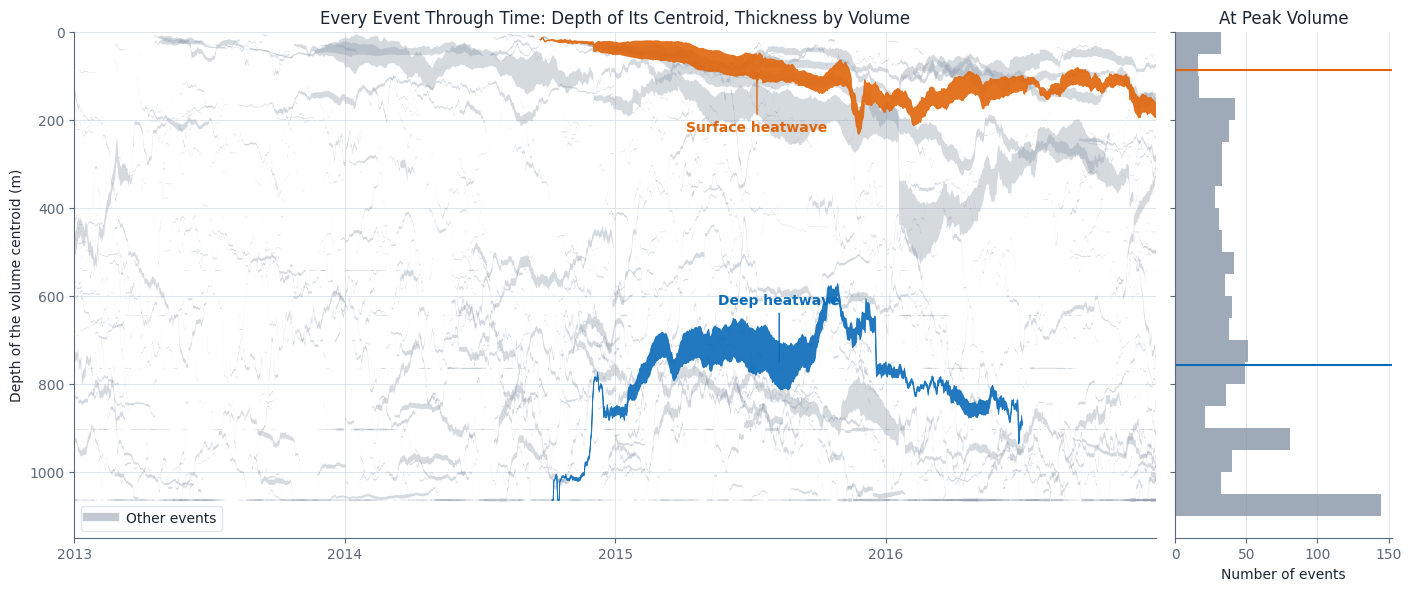

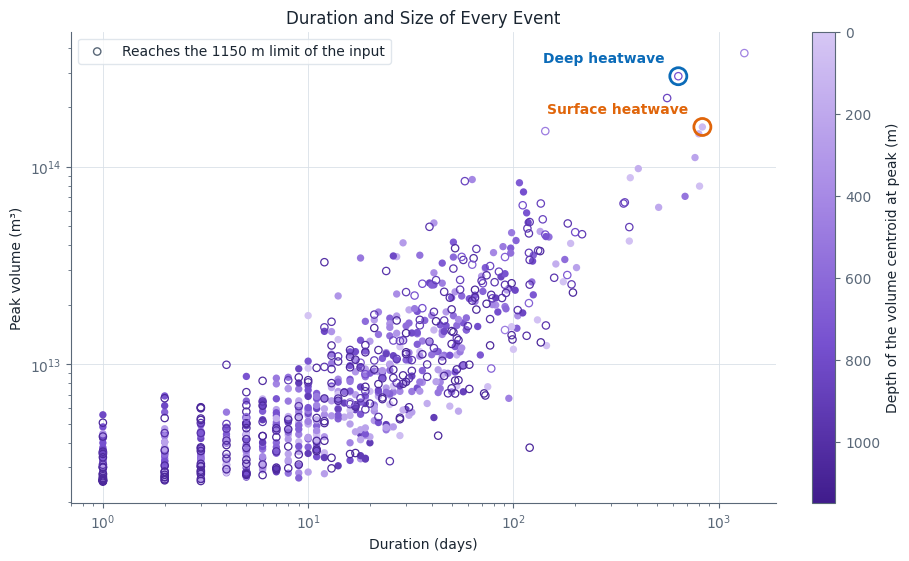

In [8]:
present = events_ds.presence.load().values  # (time, ID)
times_all = mdates.date2num(volume.time.values)
centroid_depth_at_peak = depth_centroid.sel(time=peak_time).values
reaches_floor = depth_bottom.sel(time=peak_time).values >= floor_depth - 1
peak_volume = volume.max("time").values
ID_list = volume.ID.values

# Each event is a ribbon along its centroid depth, as thick as its volume. The two followed events are in colour.
ribbon_scale = 0.12 * floor_depth / float(peak_volume.max())  # the largest event is 12% of the depth range thick
ribbons, ribbon_colours, ribbon_order = [], [], []
for position, event_id in enumerate(ID_list):
    days = np.flatnonzero(present[:, position])
    if days.size == 0:
        continue
    half = 0.5 * ribbon_scale * np.nan_to_num(volume.values[days, position])
    middle = depth_centroid.values[days, position]
    ribbons.append(np.r_[np.c_[times_all[days], middle - half], np.c_[times_all[days], middle + half][::-1]])
    highlighted = event_id in (main_id, surface_id)
    ribbon_colours.append(COLOUR[event_id] if highlighted else OTHER_COLOUR)
    ribbon_order.append(2 if highlighted else 1)
ribbon_order = np.array(ribbon_order)

fig, (ax_time, ax_hist) = plt.subplots(1, 2, figsize=(14, 5.8), width_ratios=[5, 1], sharey=True, layout="constrained")
for layer, alpha, edge in ((1, 0.35, 0.0), (2, 0.9, 0.6)):
    pick = np.flatnonzero(ribbon_order == layer)
    ax_time.add_collection(
        PolyCollection(
            [ribbons[i] for i in pick],
            facecolors=[ribbon_colours[i] for i in pick],
            alpha=alpha,
            edgecolors=[ribbon_colours[i] for i in pick],
            linewidths=edge,
        )
    )
ax_time.set(
    xlim=(times_all[0], times_all[-1]),
    ylim=(floor_depth, 0),
    ylabel="Depth of the volume centroid (m)",
    title="Every Event Through Time: Depth of Its Centroid, Thickness by Volume",
)
ax_time.xaxis_date()
ax_time.xaxis.set_major_locator(mdates.YearLocator())
ax_time.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for event_id in (main_id, surface_id):
    peak_day = mdates.date2num(peak_time.sel(ID=event_id).values)
    at_depth = float(depth_centroid.sel(ID=event_id, time=peak_time.sel(ID=event_id)))
    ax_time.annotate(
        NAME[event_id],
        (peak_day, at_depth),
        xytext=(peak_day, at_depth + (0.12 if event_id == surface_id else -0.12) * floor_depth),
        color=COLOUR[event_id],
        fontweight="bold",
        ha="center",
        arrowprops=dict(arrowstyle="-", color=COLOUR[event_id], linewidth=1.0),
    )
ax_time.legend(handles=[Line2D([], [], color=OTHER_COLOUR, linewidth=6, alpha=0.5, label="Other events")], loc="lower left")

bins = np.linspace(0, floor_depth, 24)
ax_hist.hist(centroid_depth_at_peak, bins=bins, orientation="horizontal", color=OTHER_COLOUR, alpha=0.8)
for event_id in (main_id, surface_id):
    ax_hist.axhline(float(depth_centroid.sel(ID=event_id, time=peak_time.sel(ID=event_id))), color=COLOUR[event_id], linewidth=1.5)
ax_hist.set(xlabel="Number of events", title="At Peak Volume")
ax_hist.grid(True, axis="y", alpha=0.0)
plt.show()

fig, ax_scatter = plt.subplots(figsize=(9, 5.5), layout="constrained")
for hollow in (False, True):
    pick = reaches_floor == hollow
    scatter = ax_scatter.scatter(
        duration.values[pick],
        peak_volume[pick],
        c=None if hollow else centroid_depth_at_peak[pick],
        edgecolors=DEPTH_CMAP(centroid_depth_at_peak[pick] / floor_depth) if hollow else "none",
        facecolors="none" if hollow else None,
        s=28,
        linewidths=0.9,
        cmap=None if hollow else DEPTH_CMAP,
        vmin=None if hollow else 0,
        vmax=None if hollow else floor_depth,
    )
    if not hollow:
        fig.colorbar(scatter, ax=ax_scatter, label="Depth of the volume centroid at peak (m)").ax.invert_yaxis()
for event_id in (main_id, surface_id):
    x, y = float(duration.sel(ID=event_id)), float(volume.sel(ID=event_id).max())
    ax_scatter.scatter([x], [y], s=150, facecolors="none", edgecolors=COLOUR[event_id], linewidths=2)
    ax_scatter.annotate(
        NAME[event_id], (x, y), xytext=(-10, 10), textcoords="offset points", ha="right", color=COLOUR[event_id], fontweight="bold"
    )
ax_scatter.set(
    xscale="log", yscale="log", xlabel="Duration (days)", ylabel="Peak volume (m³)", title="Duration and Size of Every Event"
)
ax_scatter.scatter([], [], facecolors="none", edgecolors=MUTED, s=28, label=f"Reaches the {floor_depth:.0f} m limit of the input")
ax_scatter.legend(loc="upper left")
plt.show()

## 3. Events as Isosurfaces

`draw_scene` draws each heatwave from its shape on every level. The distance to the shape's edge is interpolated between
the levels onto a uniform depth grid (the first cell of this notebook prints how the thickness grows with depth), lightly
smoothed, and marching cubes extracts the surface at the edge. Every triangle is coloured by the local temperature anomaly, with a colour
ramp for each heatwave. The shapes therefore taper between levels and do not step at
each layer interface. This is for display only: every number in the figures comes from the unsmoothed data. A cell below
prints how far the drawn shape strays from the cells. The surface is lit in the plot's stretched coordinates, so
depth stays legible at this vertical exaggeration.

The scene is an exploded view. The surface anomaly floats above the box as a plate, with the outline of each event on it,
and each event also casts its footprint on the floor. The other tracked events are outlined
thinly on the plate and the maps and are not drawn as bodies. All triangles of the box go into one collection, so
`matplotlib` sorts them together and the events occlude each other correctly.

The box contains the deep heatwave's footprint over its whole life and the surface heatwave's footprint on the peak day, with
a margin.

In [9]:
def footprint_bounds(footprint):
    """(lat0, lat1, lon0, lon1) of the True cells of a (lat, lon) mask."""
    lat_any, lon_any = footprint.any("lon").values, footprint.any("lat").values
    return footprint.lat.values[lat_any][[0, -1]], footprint.lon.values[lon_any][[0, -1]]


# The box contains the deep heatwave's whole footprint and the surface heatwave's footprint on the peak day.
peak_ids = events_ds.ID_field.sel(time=main_peak).compute()
footprints = [main_metrics.days_occupied > 0, (peak_ids == surface_id).any("depth"), (peak_ids == main_id).any("depth")]
lat_ranges, lon_ranges = zip(*(footprint_bounds(footprint) for footprint in footprints))
render_box = {
    "lat": slice(float(min(r[0] for r in lat_ranges)) - margin, float(max(r[1] for r in lat_ranges)) + margin),
    "lon": slice(float(min(r[0] for r in lon_ranges)) - margin, float(max(r[1] for r in lon_ranges)) + margin),
}
print(
    f"render_box: lat {render_box['lat'].start:.1f} to {render_box['lat'].stop:.1f}, lon {render_box['lon'].start:.1f} to {render_box['lon'].stop:.1f}"
)

render_box: lat 31.2 to 57.6, lon -144.4 to -122.2


In [10]:
# The 3-D scene. Drawing happens in plot coordinates (lon, lat, -depth in m) and the box aspect stretches depth.
box_mask = mask.sel(**render_box)
box_lat, box_lon, box_depth = box_mask.lat.values, box_mask.lon.values, box_mask.depth.values
BOX_HEIGHT = 9.0  # height of the drawn box in degrees of latitude on the plot
box_aspect = np.array([(box_lon[-1] - box_lon[0]) * np.cos(np.deg2rad(box_lat.mean())), box_lat[-1] - box_lat[0], BOX_HEIGHT])
exaggeration = 111.2e3 * (BOX_HEIGHT / floor_depth)
wet_at_floor = box_mask.isel(depth=-1).values
wet_at_surface = box_mask.isel(depth=0).values
level_top, level_bottom = bounds.values[:, 0], bounds.values[:, 1]

# The shapes are interpolated between the levels on a uniform depth grid, so a vertical surface tapers between levels
# and does not step at every layer interface. The levels are 1 m thick at the top and up to 171 m thick at the bottom.
DZ = 10.0
z_uniform = np.arange(DZ / 2, floor_depth, DZ)
level_of_z = np.clip(np.searchsorted(level_bottom, z_uniform), 0, box_depth.size - 1)
level_centre = 0.5 * (level_top + level_bottom)
upper_level = np.clip(np.searchsorted(level_centre, z_uniform), 1, box_depth.size - 1)
lower_level = upper_level - 1
level_weight = np.clip((z_uniform - level_centre[lower_level]) / (level_centre[upper_level] - level_centre[lower_level]), 0, 1)
FAR = 40.0  # horizontal cells: the distance outside an event wherever it has no neighbour level
SMOOTHING = 1.0  # sigma of the light Gaussian on the distance field, in grid cells
PLATE_GAP = 0.42 * floor_depth  # metres the surface plate floats above the box


def distance_by_level(in_event, step):
    """Signed distance to the event's edge on each level, in horizontal cells of the drawn grid, negative inside.

    A level with no event takes the distance to the shape on a neighbouring level, so the shape meets its own layer
    interface and stops there.
    """
    masks = in_event[:, ::step, ::step]
    fields = np.full(masks.shape, FAR, "f4")
    occupied = masks.any(axis=(1, 2))
    for k in np.flatnonzero(occupied):
        fields[k] = distance_transform_edt(~masks[k]) - distance_transform_edt(masks[k])
    for k in np.flatnonzero(~occupied):
        neighbours = [np.abs(fields[j]) for j in (k - 1, k + 1) if 0 <= j < masks.shape[0] and occupied[j]]
        if neighbours:
            fields[k] = np.minimum.reduce(neighbours)
    return fields


def smooth_field(in_event, step=2):
    """The event as a field on the uniform depth grid, positive inside: its distance field interpolated between levels."""
    fields = distance_by_level(in_event, step)
    distance = fields[lower_level] * (1 - level_weight)[:, None, None] + fields[upper_level] * level_weight[:, None, None]
    return gaussian_filter(-distance, sigma=SMOOTHING, mode=("nearest", "constant", "constant"), cval=-FAR)


def event_triangles(in_event, anomaly, cmap, norm, step=2):
    """Triangles (lon, lat, -depth) of one event's surface, their colours and smooth normals."""
    field = smooth_field(in_event, step)
    if field.max() <= 0:
        return None
    # An event that reaches the surface continues upward through the padding, so its top is cut flat at z = 0.
    padded = np.pad(field, ((3, 1), (1, 1), (1, 1)), mode="constant", constant_values=-FAR)
    padded[1:3, 1:-1, 1:-1] = field[:1]
    padded[0] = -FAR
    vertices, faces, _, _ = marching_cubes(padded, 0.0)
    k, j, i = vertices.T
    depth = np.clip((k - 3 + 0.5) * DZ, 0, floor_depth)
    xyz = np.c_[
        np.interp((i - 1) * step, np.arange(box_lon.size), box_lon),
        np.interp((j - 1) * step, np.arange(box_lat.size), box_lat),
        -depth,
    ]
    plotted = xyz * box_aspect / np.array([box_lon[-1] - box_lon[0], box_lat[-1] - box_lat[0], floor_depth])
    face_normals = np.cross(plotted[faces[:, 1]] - plotted[faces[:, 0]], plotted[faces[:, 2]] - plotted[faces[:, 0]])
    vertex_normals = np.zeros_like(plotted)
    for corner in range(3):
        np.add.at(vertex_normals, faces[:, corner], face_normals)

    centre = xyz[faces].mean(axis=1)
    level = level_of_z[np.clip(((-centre[:, 2]) / DZ).astype(int), 0, z_uniform.size - 1)]
    row = np.clip(np.searchsorted(box_lat, centre[:, 1]), 0, box_lat.size - 1)
    column = np.clip(np.searchsorted(box_lon, centre[:, 0]), 0, box_lon.size - 1)
    values = np.nan_to_num(anomaly[level, row, column])
    colours = cmap(norm(np.clip(values, 0.0, None)))[:, :3]
    return xyz[faces], colours, vertex_normals[faces].mean(axis=1)


def lit(colours, normals, camera):
    """Two-sided diffuse and specular shading for a camera (elevation, azimuth) in degrees."""
    elevation, azimuth = np.deg2rad(camera)
    view = np.array([np.cos(elevation) * np.cos(azimuth), np.cos(elevation) * np.sin(azimuth), np.sin(elevation)])
    light = np.array([-0.45, -0.55, 0.7]) / np.linalg.norm([-0.45, -0.55, 0.7])
    halfway = (light + view) / np.linalg.norm(light + view)
    normals = normals / np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
    normals = normals * np.where(normals @ view < 0, -1.0, 1.0)[:, None]
    diffuse = np.clip(normals @ light, 0, 1)[:, None]
    specular = np.clip(normals @ halfway, 0, 1)[:, None] ** 24
    ambient, diffuse_weight, specular_weight = SHADE
    return np.clip(colours * (ambient + diffuse_weight * diffuse) + specular_weight * specular, 0, 1)


def grid_quads(where, z, step):
    """Two triangles per grid box of `where` (coarsened by `step`) at height z, with their row and column."""
    rows, columns = np.nonzero(where[::step, ::step])
    lat, lon = box_lat[::step], box_lon[::step]
    dlat, dlon = lat[1] - lat[0], lon[1] - lon[0]
    x0, y0 = lon[columns], lat[rows]
    corners = np.stack([np.c_[x0, y0], np.c_[x0 + dlon, y0], np.c_[x0 + dlon, y0 + dlat], np.c_[x0, y0 + dlat]], axis=1)
    corners = np.concatenate([corners, np.full((*corners.shape[:2], 1), z)], axis=2)
    triangles = np.r_[corners[:, [0, 1, 2]], corners[:, [0, 2, 3]]]
    return triangles, np.r_[rows, rows] * step, np.r_[columns, columns] * step


def outline(footprint, z):
    """Contour segments (lon, lat, z) around a (lat, lon) mask."""
    segments = []
    for segment in find_contours(np.pad(footprint.astype(float), 1), 0.5):
        lon = np.interp(segment[:, 1] - 1, np.arange(box_lon.size), box_lon)
        lat = np.interp(segment[:, 0] - 1, np.arange(box_lat.size), box_lat)
        segments.append(np.c_[lon, lat, np.full(lon.size, z)])
    return segments


def ramps(anomaly_ids, anomaly):
    """One colour map and norm per event. The upper limit is the 99th percentile of the anomaly inside the event."""
    result = {}
    for event_id, cmap in ((main_id, MAIN_CMAP), (surface_id, SURFACE_CMAP)):
        inside = anomaly[anomaly_ids == event_id]
        top = float(np.ceil(np.nanpercentile(inside, 99) * 10) / 10)
        result[event_id] = (cmap, PowerNorm(0.6, vmin=0.0, vmax=top))
    return result


def draw_scene(fig, rect, ids, anomaly, norms, thr_surface=None, camera=(16, -48), zoom=1.0, plate=True):
    """Draw the deep and surface heatwaves of one day, (depth, lat, lon) arrays on `render_box`, into a 3-D axes.

    Each event has its own colour ramp. With `plate` the surface anomaly floats above the box, coloured only where it
    passes the heatwave threshold `thr_surface`, with both events' footprints outlined on it and the other tracked
    events outlined thinly. The two footprints are also outlined on the floor.
    """
    ax = fig.add_axes(rect, projection="3d", computed_zorder=False, facecolor="none")
    azimuth = np.deg2rad(camera[1])
    wall_lat = box_lat[-1] if np.sin(azimuth) < 0 else box_lat[0]  # the edges of the box furthest from the camera
    wall_lon = box_lon[0] if np.cos(azimuth) > 0 else box_lon[-1]

    floor, rows, columns = grid_quads(wet_at_floor, -floor_depth, step=3)
    triangles, colours = [floor], [np.tile([*FLOOR_RGB, 1.0], (len(floor), 1))]
    land, _, _ = grid_quads(~wet_at_surface, 0.0, step=2)
    triangles.append(land)
    colours.append(np.tile([*LAND_RGB, 1.0], (len(land), 1)))

    in_events = {event_id: ids == event_id for event_id in (main_id, surface_id)}
    for event_id, in_event in in_events.items():
        cmap, norm = norms[event_id]
        surface = event_triangles(in_event, anomaly, cmap, norm)
        if surface is not None:
            triangles.append(surface[0])
            colours.append(np.c_[lit(surface[1], surface[2], camera), np.ones(len(surface[0]))])

    if plate:
        plate_tri, plate_rows, plate_cols = grid_quads(wet_at_surface, PLATE_GAP, step=2)
        values = np.nan_to_num(anomaly[0][plate_rows, plate_cols])
        plate_colours = heat_rgba(values, thr_surface[plate_rows, plate_cols])
        triangles.append(plate_tri)
        colours.append(plate_colours)
    all_colours = np.concatenate(colours)
    # Each polygon gets a thin edge in its own colour to hide the seams between them.
    ax.add_collection3d(
        Poly3DCollection(np.concatenate(triangles), facecolors=all_colours, edgecolors=all_colours, linewidths=0.3, zsort="average")
    )

    # Footprints outlined on the floor and, with the coast, on the plate.
    for event_id, in_event in in_events.items():
        for segment in outline(in_event.any(axis=0), -floor_depth):
            ax.plot(*segment.T, color=COLOUR[event_id], linewidth=1.0, zorder=5)
        if plate and event_id == surface_id:
            for segment in outline(in_event.any(axis=0), PLATE_GAP):
                ax.plot(*segment.T, color=COLOUR[event_id], linewidth=1.6, zorder=6)
    if plate:
        other_at_surface = (ids[0] > 0) & ~np.isin(ids[0], [main_id, surface_id])
        for segment in outline(other_at_surface, PLATE_GAP):
            ax.plot(*segment.T, color=NEUTRAL, linewidth=0.6, zorder=6)
    for segment in outline(wet_at_surface, 0.0):
        ax.plot(*segment.T, color=COAST, linewidth=0.5, zorder=5)
        if plate:
            ax.plot(segment[:, 0], segment[:, 1], np.full(len(segment), PLATE_GAP), color=COAST, linewidth=0.5, zorder=6)

    # The frame of the box
    z_top = -0.0
    for z in (-floor_depth, z_top):
        ax.plot(
            [box_lon[0], box_lon[-1], box_lon[-1], box_lon[0], box_lon[0]],
            [box_lat[0], box_lat[0], box_lat[-1], box_lat[-1], box_lat[0]],
            [z] * 5,
            color=FRAME,
            linewidth=0.8,
            zorder=1,
        )
    for lon_edge, lat_edge in (
        (wall_lon, wall_lat),
        (wall_lon, box_lat[0] if wall_lat == box_lat[-1] else box_lat[-1]),
        (box_lon[-1] if wall_lon == box_lon[0] else box_lon[0], wall_lat),
    ):
        ax.plot([lon_edge] * 2, [lat_edge] * 2, [-floor_depth, 0], color=FRAME, linewidth=0.8, zorder=1)
    # A depth scale on the front-left edge of the box
    ax.plot([box_lon[0]] * 2, [box_lat[0]] * 2, [0, -1000], color=MUTED, linewidth=1.2, zorder=10)
    for depth in (0, 250, 500, 750, 1000):
        ax.plot([box_lon[0], box_lon[0] - 0.25], [box_lat[0]] * 2, [-depth] * 2, color=MUTED, linewidth=1.2, zorder=10)
        ax.text(
            box_lon[0] - 0.35, box_lat[0], -depth, f"{depth} m" if depth else "0", color=MUTED, fontsize=8, ha="right", va="center"
        )
    if plate:
        ax.text(box_lon[0] - 0.35, box_lat[0], 130, "Depth", color=MUTED, fontsize=9.5, ha="right", va="bottom")
        ax.text(box_lon[0], box_lat[0], PLATE_GAP, "Sea surface", color=MUTED, fontsize=10, ha="right", va="center")
    top = PLATE_GAP if plate else 0.0
    ax.set(xlim=(box_lon[0], box_lon[-1]), ylim=(box_lat[0], box_lat[-1]), zlim=(-floor_depth, top))
    ax.set_box_aspect(tuple(box_aspect * np.array([1, 1, (floor_depth + top) / floor_depth])), zoom=zoom)
    ax.view_init(elev=camera[0], azim=camera[1])
    ax.set_axis_off()
    # The 3-D axes are drawn in a square window and the zoom pushes the box past its edges. Without this the scene is clipped there.
    for artist in [*ax.collections, *ax.lines, *ax.texts]:
        artist.set_clip_on(False)
    return ax

Anomaly alone does not make a heatwave. The plate and the maps colour a cell only where its anomaly passes the seasonal
threshold of that day of the year, which the preprocessing notebook stored as `thresholds`, and show a faint neutral below
it. The check after the helpers confirms that this rule reproduces `extreme_events` on the peak day.

In [11]:
def load_day(day):
    """The event IDs and anomalies of one day on `render_box`, as (depth, lat, lon) arrays."""
    day_fields = xr.Dataset(
        {"ids": events_ds.ID_field.sel(time=day, **render_box), "anomaly": extremes_ds.dat_anomaly.sel(time=day, **render_box)}
    )
    day_fields = day_fields.compute()
    return day_fields.ids.values, day_fields.anomaly.values


DEEP_LEVEL = int(np.abs(extremes_ds.depth.values - 500.0).argmin())  # the level nearest 500 m, shown beside the surface
with monitor.stage("Heatwave thresholds"):
    # The seasonal threshold of every day of the year at the two levels shown, held on the client for the movie
    thresholds_box = extremes_ds.thresholds.isel(depth=[0, DEEP_LEVEL]).sel(**render_box).compute()


def threshold_slices(day):
    """The heatwave threshold at the surface and at the deep level on one day, as a (2, lat, lon) array."""
    return thresholds_box.sel(dayofyear=int(day.dayofyear)).values


def heat_rgba(anomaly, threshold):
    """Colour the anomaly where it passes the heatwave threshold. Below it, a faint neutral that keeps the structure."""
    anomaly = np.nan_to_num(anomaly)
    passed = anomaly > np.nan_to_num(threshold, nan=np.inf)
    return np.where(passed[..., None], HEAT_CMAP(HEAT_NORM(anomaly)), QUIET_CMAP(HEAT_NORM(anomaly)))


heat_main, heat_surface = main_metrics.heat / zettajoule, surface_metrics.heat / zettajoule
hidden_main, hidden_surface = main_metrics.hidden, surface_metrics.hidden
LABEL = NAME
HEADLINE = "One marine heatwave lay above another in the northeast Pacific"


def style_axes(ax, spines=("left", "bottom")):
    for side in ("left", "bottom", "top", "right"):
        ax.spines[side].set_visible(side in spines)
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=8.5)


def timeline(ax, day, marks=(), cursor=True, title="Heat above normal (ZJ, 10²¹ joules)", film=False):
    """Excess heat of both events, each line named, with the day marked by a dotted cursor and its date.

    With `film` the names and the title hold still from frame to frame, clear of the lines and the moving date.
    """
    top = 1.15 * float(max(heat_main.max(), heat_surface.max()))
    for series, colour, event_id, height in (
        (heat_surface, SURFACE_COLOUR, surface_id, 0.72),
        (heat_main, MAIN_COLOUR, main_id, 0.22),
    ):
        ax.plot(series.time.values, series.values, color=colour, linewidth=1.8)
        if film:
            ax.annotate(
                LABEL[event_id],
                (1.0, height),
                xycoords="axes fraction",
                xytext=(6, 0),
                textcoords="offset points",
                color=colour,
                fontsize=10.5,
                fontweight="bold",
                ha="left",
                va="center",
                annotation_clip=False,
            )
        else:
            away = series.where(abs(series.time - np.datetime64(day)) > np.timedelta64(120, "D"))  # clear of the cursor
            ax.annotate(
                LABEL[event_id],
                (away.idxmax("time").values, float(away.max())),
                xytext=(0, 6),
                textcoords="offset points",
                color=colour,
                fontsize=10.5,
                fontweight="bold",
                ha="center",
                va="bottom",
            )
        if cursor:
            ax.scatter([day], [float(series.sel(time=day, method="nearest"))], s=24, color=colour, zorder=5)
    if cursor:
        ax.axvline(day, color=INK, linewidth=0.9)
    for mark in marks:
        ax.axvline(mark, color=INK, linewidth=0.5, alpha=0.5, linestyle=":")
    if cursor:
        ax.annotate(
            f"{pd.Timestamp(day):%-d %b %Y}",
            (day, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(0, 4),
            textcoords="offset points",
            color=INK,
            fontsize=9.5,
            ha="center",
            va="bottom",
            annotation_clip=False,
        )
    if film:
        ax.text(0.005, 0.95, title, transform=ax.transAxes, fontsize=9, color=MUTED, va="top")
    else:
        ax.text(0.0, 1.04, title, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
    ax.set_xlim(
        min(heat_main.time.values[0], heat_surface.time.values[0]), max(heat_main.time.values[-1], heat_surface.time.values[-1])
    )
    ax.set_ylim(0, top)
    ax.set_yticks([0, 0.5, 1.0])
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.grid(False)
    style_axes(ax)


def frame_info(day):
    """What one day's labels need, as plain values, so a movie frame carries no event series."""
    info = {}
    for event_id in (main_id, surface_id):
        if float(volume.sel(ID=event_id, time=day)) <= 0:
            continue
        lat_c, lon_c = (float(centroid.sel(component=c, ID=event_id, time=day)) for c in (0, 1))
        top, bottom = float(depth_top.sel(ID=event_id, time=day)), float(depth_bottom.sel(ID=event_id, time=day))
        at_limit = bottom >= floor_depth - 1
        if event_id == surface_id:
            detail = f"Reaches {bottom:,.0f} m down"
        else:
            detail = f"From {top:,.0f} m down to {bottom:,.0f} m" + ("\nwhere the data end" if at_limit else "")
        info[event_id] = {
            "anchor": (lon_c, lat_c, -float(depth_centroid.sel(ID=event_id, time=day)) if event_id == main_id else -20.0),
            "name": LABEL[event_id],
            "detail": detail,
            "top": top,
            "bottom": bottom,
            "at_limit": at_limit,
            "hidden": float(main_metrics.hidden.sel(time=day) if event_id == main_id else surface_metrics.hidden.sel(time=day)),
        }
    return info


def direct_label(ax, point, name, detail, offset, colour):
    """A name in the event's colour with a thin leader to a (lon, lat, -depth) point of the scene, and a line of detail beneath."""
    x, y, _ = proj3d.proj_transform(*point, ax.get_proj())
    ax.annotate(
        name,
        (x, y),
        xytext=offset,
        textcoords=ax.figure.transFigure,
        color=colour,
        fontsize=13,
        fontweight="bold",
        va="bottom",
        arrowprops=dict(arrowstyle="-", color=colour, linewidth=0.9, shrinkA=3, shrinkB=0, relpos=(0, 0.2)),
    )
    ax.figure.text(offset[0], offset[1] - 0.006, detail, color=MUTED, fontsize=10, va="top")


BAR_LENGTH, BAR_HEIGHT = 0.12, 0.008  # the life-cycle figure's colour keys


def key_bar(fig, x, y, cmap, norm, label=None, label_colour=MUTED):
    """A short thin horizontal colour key with its two end values and a unit, left-aligned at (x, y) in figure fractions."""
    bar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=fig.add_axes([x, y, BAR_LENGTH, BAR_HEIGHT]), orientation="horizontal"
    )
    bar.set_ticks([norm.vmin, norm.vmax], labels=["0", f"{norm.vmax:g}"])
    bar.ax.tick_params(colors=MUTED, labelsize=8, length=2, pad=2)
    bar.outline.set_edgecolor(GRID)
    fig.text(x + BAR_LENGTH + 0.006, y + BAR_HEIGHT / 2, "°C", color=MUTED, fontsize=8, va="center")
    if label:
        fig.text(x, y + BAR_HEIGHT + 0.012, label, color=label_colour, fontsize=9, va="bottom")


def heat_key(fig, x, y, length):
    """The one colour key of the figure: degrees above normal, coloured only where a heatwave threshold is passed."""
    fig.text(x, y + 0.026, "Degrees above normal (°C)", color=INK, fontsize=10.5, va="bottom")
    fig.add_artist(
        Line2D([x + length - 0.093, x + length - 0.079], [y + 0.033] * 2, color=NEUTRAL, linewidth=0.9, transform=fig.transFigure)
    )
    fig.text(x + length - 0.074, y + 0.033, "Other heatwaves", color=MUTED, fontsize=8.5, va="center")
    bar = fig.colorbar(
        plt.cm.ScalarMappable(norm=HEAT_NORM, cmap=HEAT_CMAP),
        cax=fig.add_axes([x, y, length, BAR_HEIGHT]),
        orientation="horizontal",
    )
    bar.set_ticks([0, 1, 2, 3])
    bar.ax.tick_params(colors=MUTED, labelsize=8.5, length=2, pad=2)
    bar.outline.set_edgecolor(GRID)
    fig.text(
        x,
        y - 0.033,
        f"Coloured only where the heatwave threshold is passed.\nInside the heatwaves, {WARMER} is warmer.",
        color=MUTED,
        fontsize=8.5,
        va="top",
        linespacing=1.5,
    )


def render_globe(size=150):
    """The domain on a small globe, drawn once to an RGBA array: slate land and ocean and the domain's outline as a thin white box."""
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    lon0, lon1, lat0, lat1 = (float(v) for v in (mask.lon[0], mask.lon[-1], mask.lat[0], mask.lat[-1]))
    fig = plt.figure(figsize=(1, 1), dpi=size, facecolor="none")
    ax = fig.add_axes([0.02, 0.02, 0.96, 0.96], projection=ccrs.Orthographic(0.5 * (lon0 + lon1), 0.5 * (lat0 + lat1)))
    ax.set_global()
    ax.patch.set_facecolor(OCEAN)
    ax.add_feature(cfeature.LAND, facecolor=LAND, edgecolor=COAST, linewidth=0.3)
    ax.spines["geo"].set_edgecolor(FRAME)
    edge = np.linspace(0, 1, 40)
    box_lon = np.r_[lon0 + (lon1 - lon0) * edge, np.full(40, lon1), lon1 - (lon1 - lon0) * edge, np.full(40, lon0)]
    box_lat = np.r_[np.full(40, lat0), lat0 + (lat1 - lat0) * edge, np.full(40, lat1), lat1 - (lat1 - lat0) * edge]
    ax.plot(box_lon, box_lat, color=BOX_COLOUR, linewidth=0.9, transform=ccrs.Geodetic())
    fig.canvas.draw()
    image = np.asarray(fig.canvas.buffer_rgba()).copy()
    plt.close(fig)
    return image


# The globe is drawn once in each look, so a dark poster and a light figure can both carry it
globe_images, current_look = {}, LOOK
for look_name in LOOKS:
    set_look(look_name)
    globe_images[look_name] = render_globe()
set_look(current_look)
GLOBE_RECT = [0.835, 0.835, 0.075, 0.133]  # in figure fractions, the same on every 16:9 figure


def add_globe(fig):
    ax = fig.add_axes(GLOBE_RECT)
    ax.imshow(globe_images[LOOK])
    ax.set_axis_off()


def frame_text(fig, deck, source=True):
    """The headline, the deck beneath it and the source line, all left-aligned on one edge."""
    fig.text(0.04, 0.945, HEADLINE, fontsize=24, color=INK, fontweight="bold", va="center")
    fig.text(0.04, 0.893, deck, fontsize=13, color=MUTED, va="center", linespacing=1.4)
    if source:
        fig.text(
            0.04,
            0.005,
            f"Source: GLORYS12 ocean reanalysis, heatwaves tracked with marEx. Depth is stretched about {round(exaggeration, -1):.0f} times.",
            fontsize=8.5,
            color=MUTED,
            va="bottom",
        )


HERO_SCENE = [0.01, 0.20, 0.72, 0.68]  # the 3-D axes of the hero, in figure fractions


def hero_figure(day, norms, ids, anomaly, thr_surface, camera=(11, -48), zoom=1.45):
    fig = plt.figure(figsize=(16, 9), dpi=120, facecolor=FIGURE_BG)
    ax = draw_scene(fig, HERO_SCENE, ids, anomaly, norms, thr_surface, camera=camera, zoom=zoom)
    fig.canvas.draw()
    info = frame_info(day)
    deck = (
        f"On {day:%-d %B %Y}, a heatwave in the top {info[surface_id]['bottom']:,.0f} m of the ocean lay above a second one\n"
        f"that reached from {info[main_id]['top']:,.0f} m down to {info[main_id]['bottom']:,.0f} m"
        + (", the limit of the data." if info[main_id]["at_limit"] else ".")
    )
    frame_text(fig, deck)
    column = 0.65
    for event_id, height in ((surface_id, 0.50), (main_id, 0.31)):
        direct_label(
            ax, info[event_id]["anchor"], info[event_id]["name"], info[event_id]["detail"], (column, height), COLOUR[event_id]
        )
    heat_key(fig, column, 0.745, 0.26)
    add_globe(fig)
    ax_time = fig.add_axes([0.07, 0.085, 0.84, 0.115], facecolor="none")
    timeline(ax_time, day)
    return fig

Heatwave thresholds: 0.0 min, peak worker memory 7.6 GB of 224 GB (largest worker 0.7 of 14.0 GB), client 1.2 GB, spilled 0.0 GB, restarts 0


In [12]:
day_levels = [0, DEEP_LEVEL]
anomaly_day = extremes_ds.dat_anomaly.sel(time=main_peak).isel(depth=day_levels).compute().values
extreme_day = extremes_ds.extreme_events.sel(time=main_peak).isel(depth=day_levels).compute().values
threshold_day = extremes_ds.thresholds.isel(depth=day_levels).sel(dayofyear=int(main_peak.dayofyear)).compute().values
for k, name in enumerate(("surface", f"{extremes_ds.depth.values[DEEP_LEVEL]:.0f} m")):
    ocean = np.isfinite(anomaly_day[k]) & np.isfinite(threshold_day[k])
    agree = ((anomaly_day[k] > threshold_day[k]) == extreme_day[k])[ocean].mean()
    print(
        f"{name}: anomaly above the threshold matches extreme_events in {agree:.5f} of {int(ocean.sum())} ocean cells on {main_peak:%Y-%m-%d}"
    )

surface: anomaly above the threshold matches extreme_events in 1.00000 of 187652 ocean cells on 2015-08-10
541 m: anomaly above the threshold matches extreme_events in 1.00000 of 170012 ocean cells on 2015-08-10


In [13]:
ids_peak, anomaly_peak = load_day(main_peak)
in_deep = ids_peak == main_id
shown = smooth_field(in_deep) > 0  # the drawn shape, on the 10 m grid
cells = in_deep[level_of_z][:, ::2, ::2]  # the data's cells on the same grid
print(
    f"{NAME[main_id]} on {main_peak:%Y-%m-%d}: the drawn volume is {shown.sum() / cells.sum():.3f} of the cell volume, "
    f"{(shown & ~cells).sum() / shown.sum():.1%} of the drawn voxels lie outside the cells and {(cells & ~shown).sum() / cells.sum():.1%} of the cells' voxels are not drawn"
)

Deep heatwave on 2015-08-10: the drawn volume is 0.965 of the cell volume, 3.7% of the drawn voxels lie outside the cells and 7.1% of the cells' voxels are not drawn


The day of the deep heatwave's largest volume.

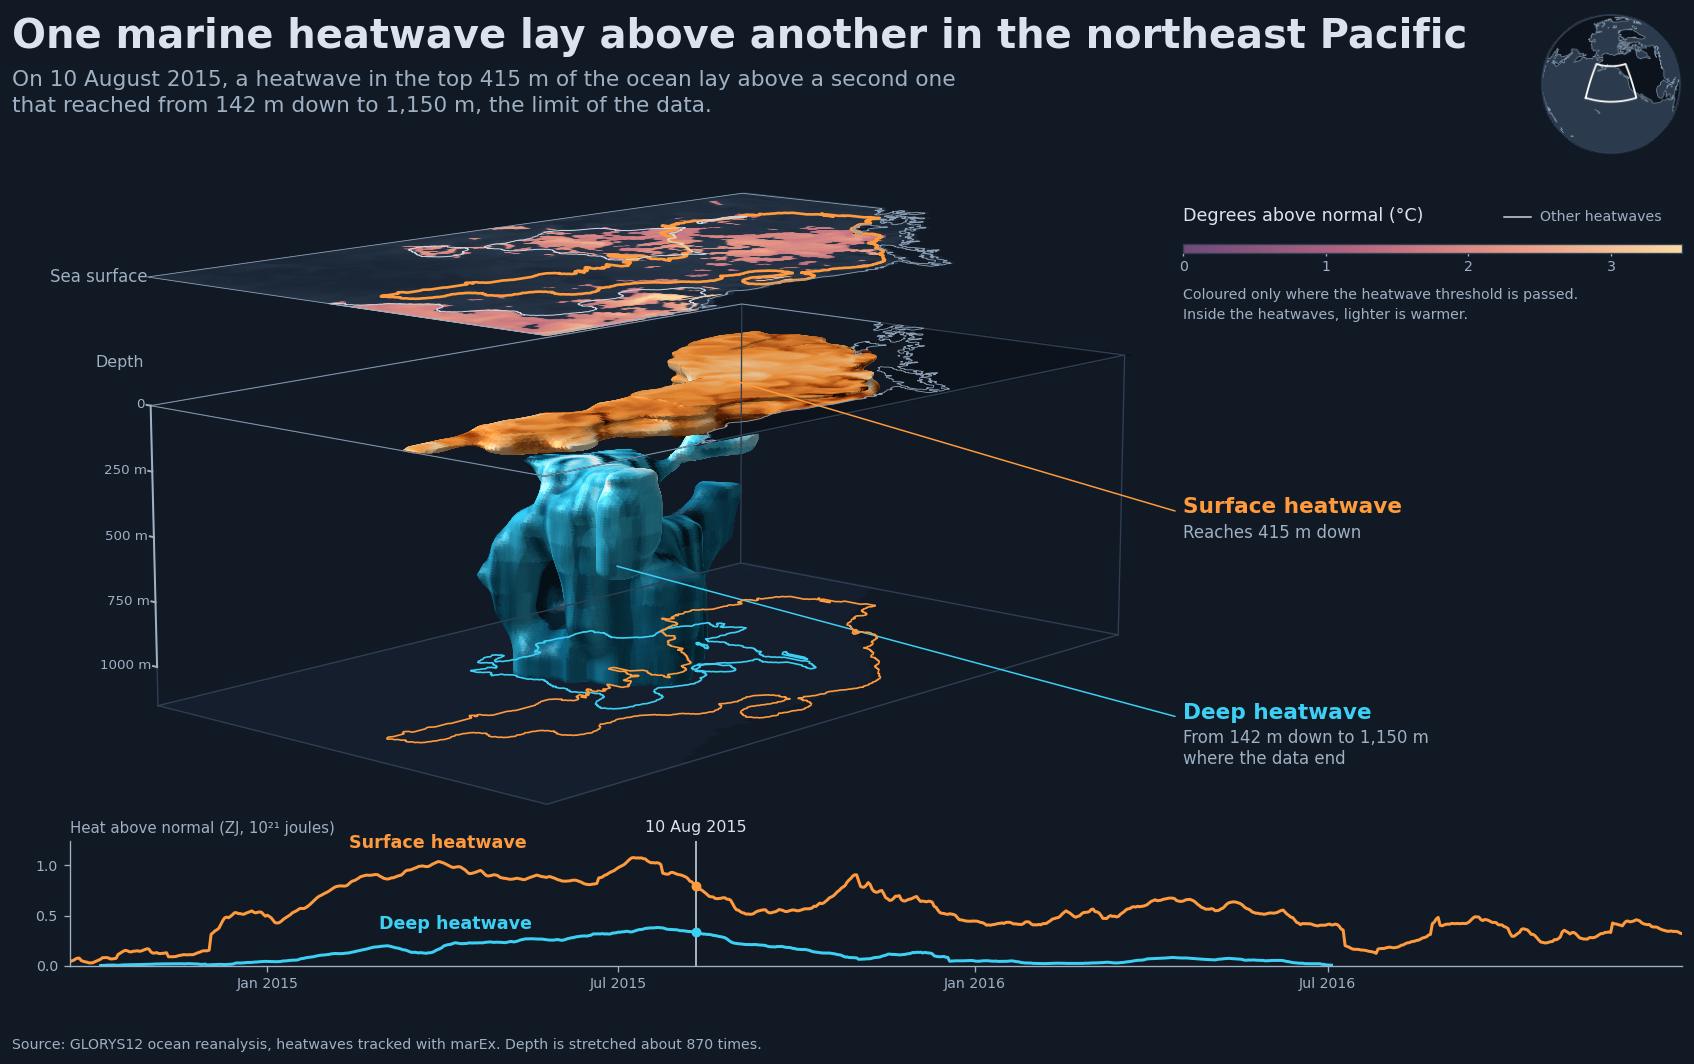

Isosurfaces: the peak: 0.9 min, peak worker memory 7.1 GB of 224 GB (largest worker 0.5 of 14.0 GB), client 1.8 GB, spilled 0.0 GB, restarts 0


In [14]:
with monitor.stage("Isosurfaces: the peak"):
    ids_peak, anomaly_peak = load_day(main_peak)
    thr_peak = threshold_slices(main_peak)
    # The poster of the README, in the dark look, as are the two films below
    page_look = set_look("dark")
    fig = hero_figure(main_peak, ramps(ids_peak, anomaly_peak), ids_peak, anomaly_peak, thr_peak[0])
    fig.savefig(plot_dir / "mhw_4d_blob.jpg", dpi=120, facecolor=FIGURE_BG, pil_kwargs={"quality": 92})
    plt.show()
    set_look(page_look)
    norms = ramps(ids_peak, anomaly_peak)  # each event's colour ramp in the look of the page, for the figures below

The heatwaves touch along 1256 voxel faces. The surface heatwave lies wholly above 4068 of the 10,226 horizontal cells the deep heatwave covers.
At the surface, a third heatwave (event 437 in this run) covers 3706 of them, the surface heatwave 2054, and 4091 have no heatwave. The cell below prints these counts.
The mean anomalies at peak heat differ by about a factor of five, so each heatwave has its own colour ramp.

In [15]:
def touching_faces(a, b):
    """Number of voxel faces shared between two boolean (depth, lat, lon) masks."""
    faces = 0
    for axis in range(3):
        later, earlier = [slice(None)] * 3, [slice(None)] * 3
        later[axis], earlier[axis] = slice(1, None), slice(None, -1)
        faces += int((a[tuple(later)] & b[tuple(earlier)]).sum() + (b[tuple(later)] & a[tuple(earlier)]).sum())
    return faces


in_main, in_surface = ids_peak == main_id, ids_peak == surface_id
column = in_main.any(axis=0)


def first_level(in_event):
    return np.where(in_event.any(axis=0), in_event.argmax(axis=0), box_depth.size)


def last_level(in_event):
    return np.where(in_event.any(axis=0), box_depth.size - 1 - in_event[::-1].argmax(axis=0), -1)


slab_above = column & in_surface.any(axis=0) & (last_level(in_surface) < first_level(in_main))
at_surface, counts = np.unique(ids_peak[0][column], return_counts=True)
print(f"The events touch along {touching_faces(in_main, in_surface)} voxel faces on {main_peak:%Y-%m-%d}")
print(
    f"The deep heatwave covers {int(column.sum())} horizontal cells, and the surface heatwave lies wholly above it in {int(slab_above.sum())} of them"
)
print("At the surface level over those cells:", {("no event" if k == 0 else int(k)): int(n) for k, n in zip(at_surface, counts)})
others = np.setdiff1d(np.unique(ids_peak[ids_peak > 0]), [main_id, surface_id])
print(f"{others.size} other tracked events have cells in the box on {main_peak:%Y-%m-%d}, none drawn")

The events touch along 1256 voxel faces on 2015-08-10
The deep heatwave covers 10226 horizontal cells, and the surface heatwave lies wholly above it in 4068 of them
At the surface level over those cells: {'no event': 4091, 90: 375, 392: 2054, 437: 3706}
17 other tracked events have cells in the box on 2015-08-10, none drawn


**Life cycle.** Eight days spread evenly over the deep heatwave's life, from one camera, so changes in shape and position
can be compared directly. Each panel gives the volume, the excess heat and the depth range on its day.

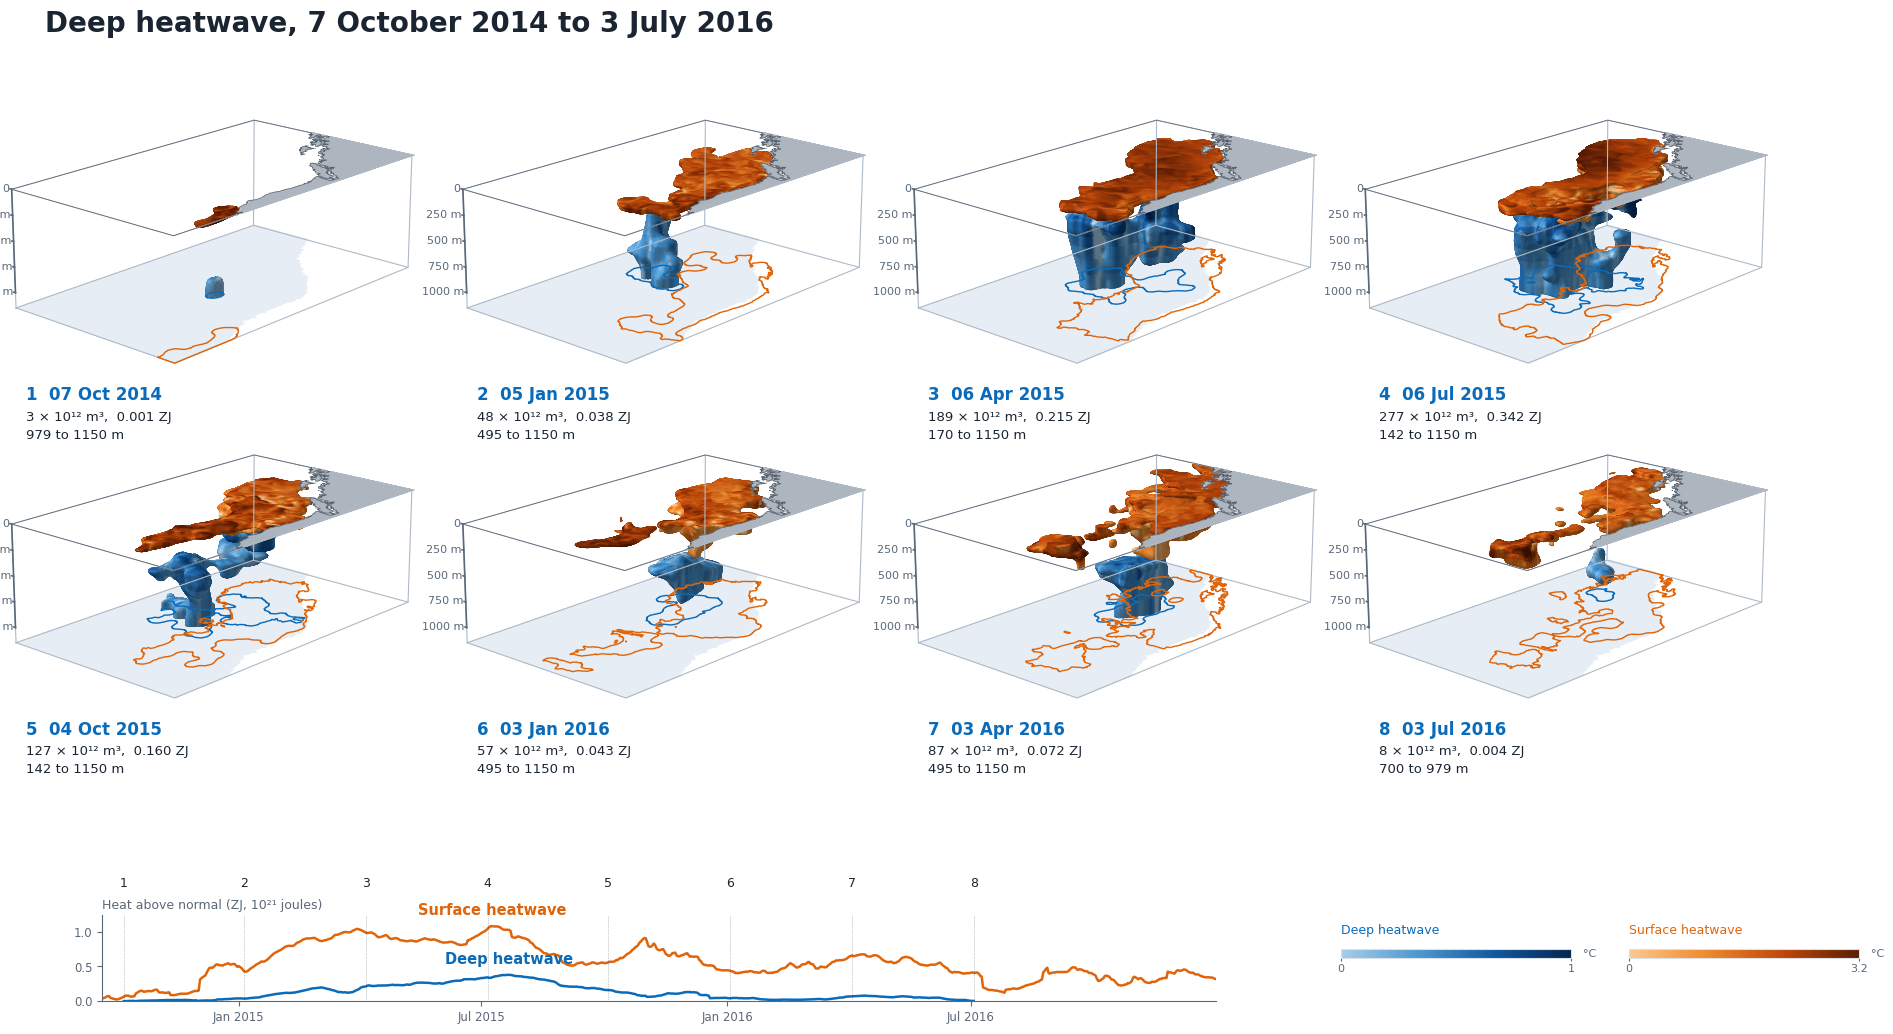

Isosurfaces: life cycle: 1.8 min, peak worker memory 8.4 GB of 224 GB (largest worker 0.8 of 14.0 GB), client 2.5 GB, spilled 0.0 GB, restarts 0


In [16]:
life_days = pd.date_range(start, end, periods=8).normalize()

with monitor.stage("Isosurfaces: life cycle"):
    fig = plt.figure(figsize=(19.2, 10.8), dpi=100, facecolor=FIGURE_BG)
    fig.text(
        0.04,
        0.95,
        f"{LABEL[main_id]}, {start:%-d %B %Y} to {end:%-d %B %Y}",
        fontsize=20,
        color=INK,
        fontweight="bold",
        va="center",
    )
    for n, day in enumerate(life_days):
        ids_day, anomaly_day_box = load_day(day)
        left, bottom = 0.03 + 0.235 * (n % 4), 0.58 - 0.31 * (n // 4)
        draw_scene(
            fig,
            [left - 0.012, bottom + 0.02, 0.22, 0.31],
            ids_day,
            anomaly_day_box,
            norms,
            camera=(18, -48),
            zoom=1.25,
            plate=False,
        )
        fig.text(left, bottom + 0.035, f"{n + 1}  {day:%d %b %Y}", fontsize=12, fontweight="bold", color=MAIN_COLOUR, va="top")
        fig.text(
            left,
            bottom + 0.012,
            f"{float(volume.sel(ID=main_id, time=day)) / 1e12:,.0f} × 10¹² m³,  {float(main_metrics.heat.sel(time=day)) / zettajoule:.3f} ZJ\n"
            f"{float(depth_top.sel(ID=main_id, time=day)):.0f} to {float(depth_bottom.sel(ID=main_id, time=day)):.0f} m",
            fontsize=9.5,
            color=INK,
            va="top",
            linespacing=1.5,
        )
    for k, event_id in enumerate((main_id, surface_id)):
        key_bar(fig, 0.715 + 0.15 * k, 0.085, *norms[event_id], label=LABEL[event_id], label_colour=COLOUR[event_id])
    ax_time = fig.add_axes([0.07, 0.045, 0.58, 0.08], facecolor="none")
    timeline(ax_time, life_days[0], marks=life_days, cursor=False)
    for n, day in enumerate(life_days):
        ax_time.annotate(
            str(n + 1),
            (day, 1.0),
            xycoords=("data", "axes fraction"),
            xytext=(0, 18),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            color=INK,
            annotation_clip=False,
        )
    plt.show()

## 4. Excess Heat Content and Hidden Volume

Testing the raw `extreme_events` at the surface instead of the tracked events raises the lifetime fractions in the table,
from 0.39 to 0.45 for the deep heatwave and from 0.57 to 0.66 for the surface heatwave.

In [17]:
rows = {}
for event_id, metrics in [(main_id, main_metrics), (surface_id, surface_metrics)]:
    rows[NAME[event_id]] = {
        "peak heat (ZJ)": float(metrics.heat.max()) / zettajoule,
        "peak heat date": str(metrics.heat.idxmax("time").values)[:10],
        "peak volume (1e15 m3)": float(metrics.volume.max()) / 1e15,
        "mean anomaly at peak heat (°C)": float(metrics.heat.max() / rho_cp / metrics.volume.sel(time=metrics.heat.idxmax("time"))),
        "mean hidden fraction": float(metrics.hidden.sum() / metrics.volume.sum()),
    }
pd.DataFrame(rows).T.round(3)

,peak heat (ZJ),peak heat date,peak volume (1e15 m3),mean anomaly at peak heat (°C),mean hidden fraction
Deep heatwave,0.380102,2015-07-22,0.287631,0.337969,0.394178
Surface heatwave,1.078072,2015-07-09,0.159079,1.687607,0.573121


Each column shows one heatwave. The upper panel is its excess heat and the lower panel its volume, split into the part that
has a heatwave at the surface above it and the hatched part that has none. The dashed line is the deep heatwave's peak day.

In [18]:
surface_wet = mask.isel(depth=0).values  # land is False; the coast comes from the model's own mask


def base_map(ax, lon, lat, extent=None):
    """An ocean-slate map axes with land drawn from the model mask, at the true aspect for its latitude."""
    ax.set_facecolor(OCEAN)
    land = np.ma.masked_where(surface_wet, np.ones(surface_wet.shape))
    ax.imshow(
        land,
        origin="lower",
        extent=[lon[0], lon[-1], lat[0], lat[-1]],
        cmap=LinearSegmentedColormap.from_list("land", [LAND, LAND]),
        interpolation="nearest",
        zorder=3,
        aspect="auto",
    )
    ax.contour(lon, lat, surface_wet.astype(float), levels=[0.5], colors=[COAST], linewidths=0.4, zorder=4)
    if extent is None:
        extent = (lon[0], lon[-1], lat[0], lat[-1])
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(1 / np.cos(np.deg2rad(0.5 * (extent[2] + extent[3]))))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(GRID)


def field_extent(footprint, pad=margin):
    """(lon0, lon1, lat0, lat1) around the True cells of a (lat, lon) mask, padded and kept inside the domain."""
    lat_range, lon_range = footprint_bounds(footprint)
    return (
        max(float(lon_range[0]) - pad, float(mask.lon[0])),
        min(float(lon_range[1]) + pad, float(mask.lon[-1])),
        max(float(lat_range[0]) - pad, float(mask.lat[0])),
        min(float(lat_range[1]) + pad, float(mask.lat[-1])),
    )


def show_field(ax, field, **kwargs):
    """Draw a (lat, lon) DataArray on a base map. NaN is left to show the ocean beneath."""
    return ax.pcolormesh(
        field.lon, field.lat, np.ma.masked_invalid(field.values), shading="nearest", zorder=2, rasterized=True, **kwargs
    )


def depth_axis(ax, ticks=(0, 10, 25, 50, 100, 200, 400, 700, 1000)):
    """A square-root depth axis, so the thin upper levels get room, with explicit ticks."""
    ax.set_yscale("function", functions=(lambda d: np.sqrt(np.clip(d, 0, None)), np.square))
    ax.set_ylim(floor_depth, 0)
    ax.set_yticks(ticks)
    ax.set_yticklabels([str(t) for t in ticks])
    ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_ylabel("Depth (m, square-root scale)")


def date_axis(ax, months=(1, 7)):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=months))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

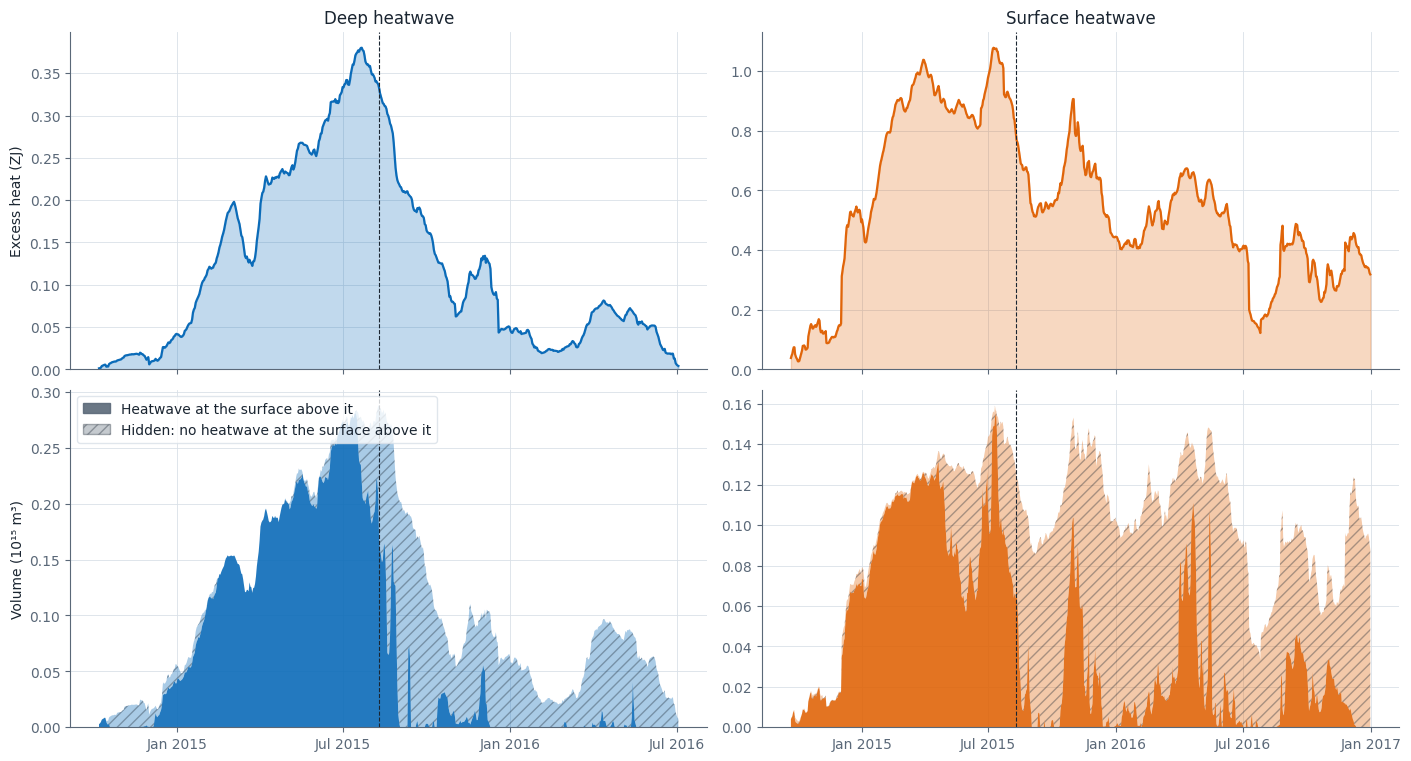

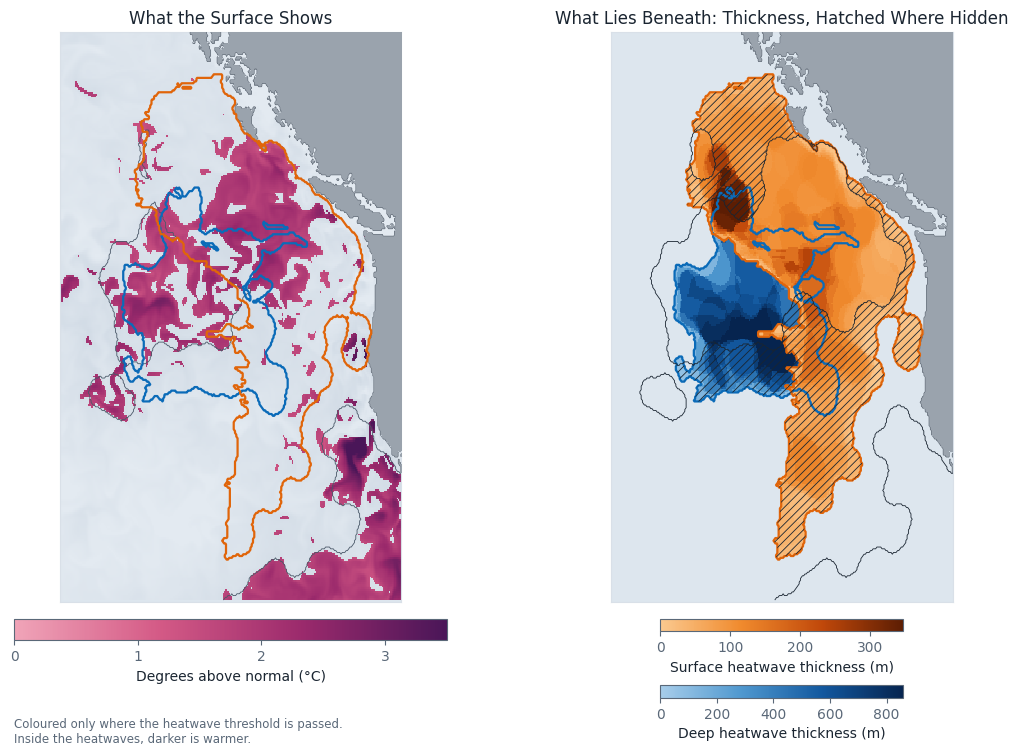

Deep heatwave on 2015-08-10: 42% of its volume is hidden
Surface heatwave on 2015-08-10: 50% of its volume is hidden


In [19]:
# Section 4: how much of each event the surface cannot see
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex="col", layout="constrained")
for column, (event_id, metrics) in enumerate(((main_id, main_metrics), (surface_id, surface_metrics))):
    colour = COLOUR[event_id]
    hidden_volume, visible_volume = metrics.hidden.values / 1e15, (metrics.volume - metrics.hidden).values / 1e15
    ax = axes[0, column]
    ax.fill_between(metrics.time.values, 0, metrics.heat.values / zettajoule, color=colour, alpha=0.25)
    ax.plot(metrics.time.values, metrics.heat.values / zettajoule, color=colour, linewidth=1.6)
    ax.set(ylim=(0, None), title=f"{NAME[event_id]}", ylabel="Excess heat (ZJ)" if column == 0 else None)
    ax = axes[1, column]
    ax.stackplot(metrics.time.values, visible_volume, hidden_volume, colors=[colour, colour], alpha=0.9, edgecolor="none")
    ax.collections[1].set(alpha=0.35, hatch="///", edgecolor=INK, linewidth=0)
    ax.set(ylim=(0, None), ylabel="Volume (10¹⁵ m³)" if column == 0 else None)
    for ax in axes[:, column]:
        date_axis(ax)
        ax.axvline(main_peak, color=INK, linewidth=0.8, linestyle="--")
axes[1, 0].legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=MUTED, alpha=0.9),
        plt.Rectangle((0, 0), 1, 1, facecolor=MUTED, alpha=0.35, hatch="///", edgecolor=INK),
    ],
    labels=["Heatwave at the surface above it", "Hidden: no heatwave at the surface above it"],
    loc="upper left",
)
plt.show()

# The peak day in map view: what the surface shows, against how thick each heatwave is beneath it
box_depth_thickness = thickness.values[:, None, None]
box_extent = (render_box["lon"].start, render_box["lon"].stop, render_box["lat"].start, render_box["lat"].stop)
box_coords = {"lat": box_lat, "lon": box_lon}
fig, (ax_sst, ax_col) = plt.subplots(1, 2, figsize=(11, 7.4), layout="constrained")
for ax in (ax_sst, ax_col):
    base_map(ax, mask.lon.values, mask.lat.values, extent=box_extent)
# Left: the anomaly at the surface, coloured only where it passes the heatwave threshold, as on the plate
ax_sst.imshow(
    heat_rgba(anomaly_peak[0], thr_peak[0]),
    origin="lower",
    extent=[box_lon[0], box_lon[-1], box_lat[0], box_lat[-1]],
    aspect=ax_sst.get_aspect(),
    interpolation="nearest",
    zorder=2,
)
ax_sst.set_xlim(box_extent[0], box_extent[1])
ax_sst.set_ylim(box_extent[2], box_extent[3])
bar = fig.colorbar(
    plt.cm.ScalarMappable(norm=HEAT_NORM, cmap=HEAT_CMAP),
    ax=ax_sst,
    orientation="horizontal",
    shrink=0.8,
    pad=0.02,
    label="Degrees above normal (°C)",
)
bar.set_ticks([0, 1, 2, 3])
bar.ax.text(
    0,
    -3.6,
    f"Coloured only where the heatwave threshold is passed.\nInside the heatwaves, {WARMER} is warmer.",
    transform=bar.ax.transAxes,
    fontsize=8.5,
    color=MUTED,
    va="top",
)
other_at_surface = (ids_peak[0] > 0) & ~np.isin(ids_peak[0], [main_id, surface_id])
ax_sst.contour(box_lon, box_lat, other_at_surface.astype(float), levels=[0.5], colors=[NEUTRAL], linewidths=0.6, zorder=5)
for ax in (ax_sst, ax_col):
    for event_id in (main_id, surface_id):
        ax.contour(
            box_lon,
            box_lat,
            (ids_peak == event_id).any(axis=0).astype(float),
            levels=[0.5],
            colors=[COLOUR[event_id]],
            linewidths=1.6,
            zorder=5,
        )
ax_sst.set_title("What the Surface Shows")
at_surface = ids_peak[0] > 0
for event_id, cmap in ((main_id, MAIN_CMAP), (surface_id, SURFACE_CMAP)):
    in_event = ids_peak == event_id
    column_thickness = np.where(in_event.any(axis=0), (in_event * box_depth_thickness).sum(axis=0), np.nan)
    shown = show_field(
        ax_col,
        xr.DataArray(column_thickness, coords=box_coords, dims=("lat", "lon")),
        cmap=cmap,
        vmin=0,
        vmax=np.nanpercentile(column_thickness, 99),
    )
    fig.colorbar(shown, ax=ax_col, orientation="horizontal", shrink=0.45, pad=0.02, label=f"{NAME[event_id]} thickness (m)")
ax_col.contour(box_lon, box_lat, at_surface.astype(float), levels=[0.5], colors=[INK], linewidths=0.6, zorder=6)
hidden_columns = np.isin(ids_peak, [main_id, surface_id]).any(axis=0) & ~at_surface
with plt.rc_context({"hatch.color": INK, "hatch.linewidth": 0.6}):
    ax_col.contourf(box_lon, box_lat, hidden_columns.astype(float), levels=[0.5, 1.5], colors="none", hatches=["////"], zorder=6)
ax_col.set_title("What Lies Beneath: Thickness, Hatched Where Hidden")
plt.show()
cell_area_box = cell_area.sel(**render_box).values
for event_id in (main_id, surface_id):
    inside = ids_peak == event_id
    hidden_share = float(
        (inside * box_depth_thickness * (~at_surface)[None] * cell_area_box[None]).sum()
        / (inside * box_depth_thickness * cell_area_box[None]).sum()
    )
    print(f"{NAME[event_id]} on {main_peak:%Y-%m-%d}: {hidden_share:.0%} of its volume is hidden")

Volume-weighted over each quarter, the deep heatwave is 2-3% hidden in the first half of 2015, about 45% in the third quarter
and above 97% in each quarter from January 2016. The surface heatwave is 2% hidden in the first quarter of 2015, 57% in the third and
71-88% through 2016. Its top is at the surface on 81% of days from July 2015, but the surface level covers a median 95% of
its footprint in the first quarter of 2015 and 3-20% from the fourth. On the deep heatwave's peak day, 42% of its volume and
50% of the surface heatwave's are hidden. The maps show that day. The left map is coloured only where the anomaly passes the
heatwave threshold, as on the plate. The thin line on the right outlines the columns where a tracked heatwave reaches the
surface, and the hatching marks the columns of the two heatwaves with no tracked heatwave at the surface above them.

## 5. Inside the Heatwaves

The area-mean anomaly inside each event at every level, against time, with the event's top, volume centroid and bottom
drawn over it. The depth axis is a square root, so the thin upper levels get room, and each event has its own colours.

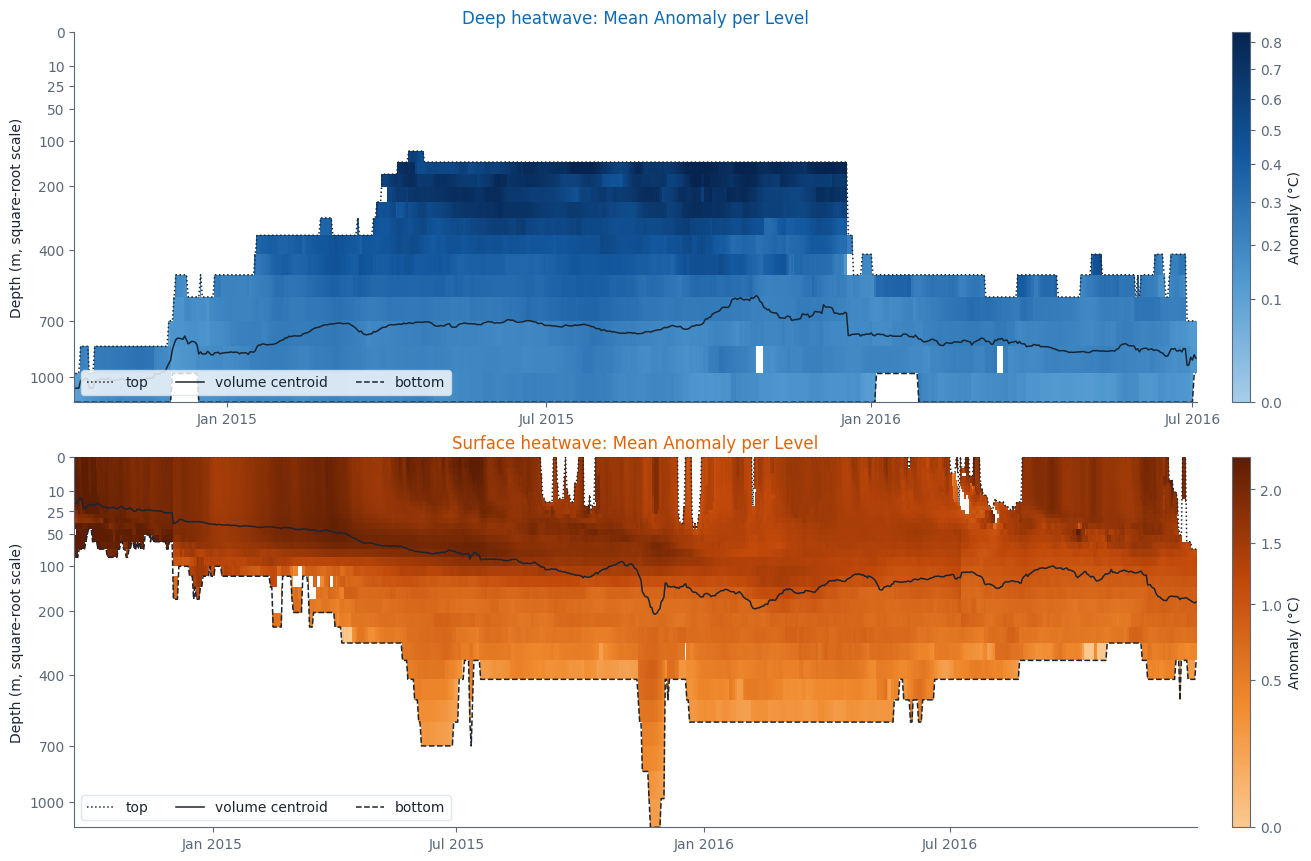

In [20]:
# Section 5: the mean anomaly inside each event at every level, against time
depth_edges = np.r_[level_top, level_bottom[-1]]
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), layout="constrained")
for ax, event_id, metrics, cmap in [
    (axes[0], main_id, main_metrics, MAIN_CMAP),
    (axes[1], surface_id, surface_metrics, SURFACE_CMAP),
]:
    times = metrics.time.values
    half_day = np.timedelta64(12, "h")
    time_edges = np.r_[times[0] - half_day, times + half_day]
    limit = float(metrics.profile.quantile(0.99))
    mesh = ax.pcolormesh(
        time_edges,
        depth_edges,
        metrics.profile.values.T,
        cmap=cmap,
        norm=PowerNorm(0.6, vmin=0, vmax=limit),
        shading="flat",
        rasterized=True,
    )
    for series, style, label in [(depth_top, ":", "top"), (depth_centroid, "-", "volume centroid"), (depth_bottom, "--", "bottom")]:
        ax.plot(times, series.sel(ID=event_id).sel(time=times), color=INK, linestyle=style, linewidth=1.1, label=label)
    depth_axis(ax)
    date_axis(ax)
    ax.grid(False)
    ax.set_title(f"{NAME[event_id]}: Mean Anomaly per Level", color=COLOUR[event_id])
    ax.legend(loc="lower left", ncol=3)
    fig.colorbar(mesh, ax=ax, label="Anomaly (°C)", pad=0.01)
plt.show()

## 6. Lifetime Footprint

Each column of the map summarised over each event's whole life: the day it first arrived, how many days it stayed,
the deepest level it reached, and the largest excess heat the column contained per square metre. Each row of maps is
zoomed to the event's footprint.

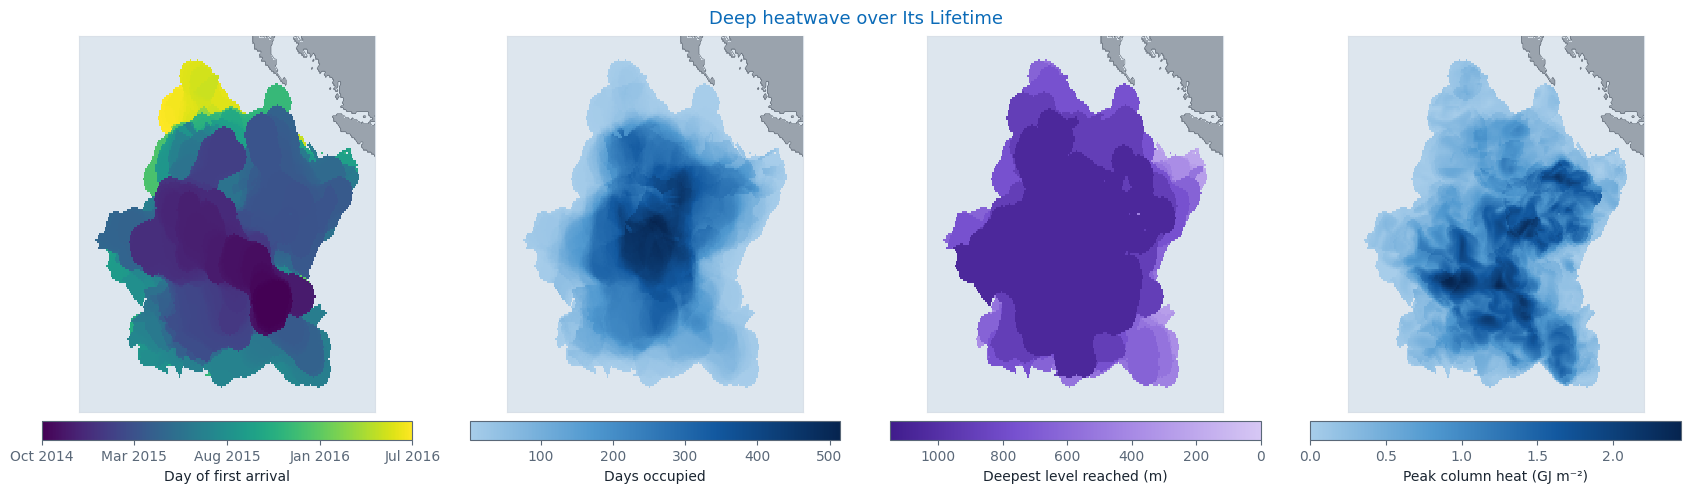

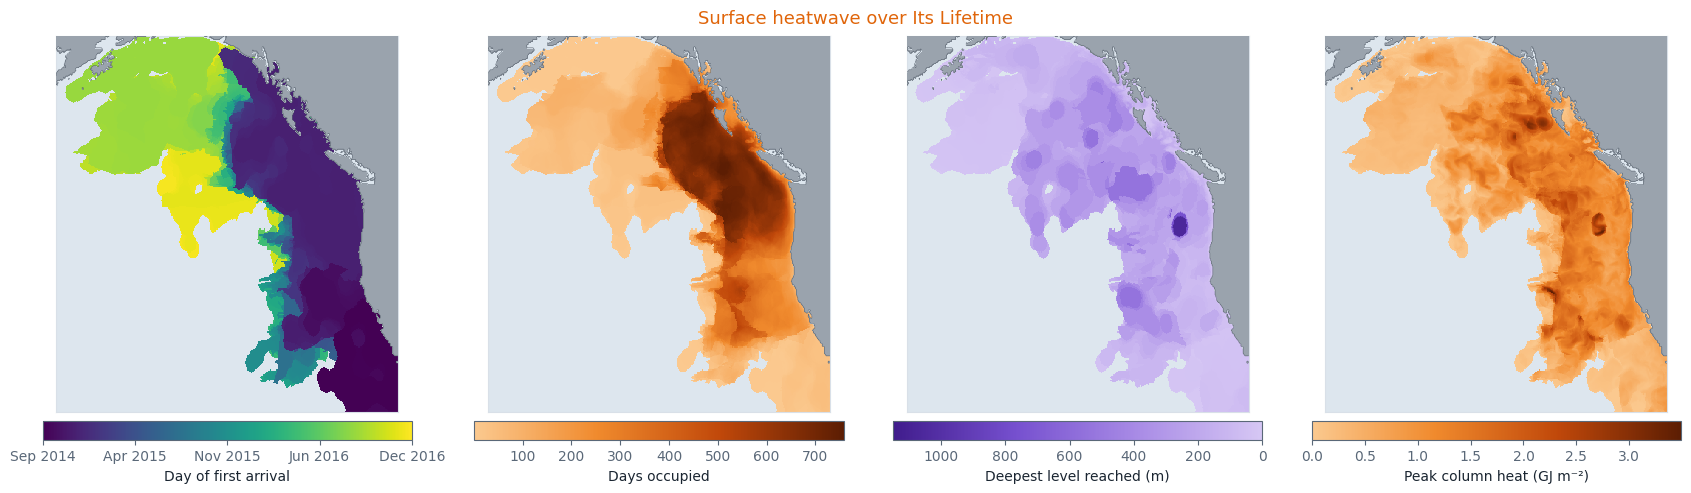

In [21]:
# Section 6: each column of the map summarised over the event's whole life
def footprint_figure(event_id, metrics, cmap):
    extent = field_extent(metrics.days_occupied > 0, pad=1.0)
    start_of_life = metrics.time.values[0]
    arrival = metrics.first_day  # days after the event's first day
    panels = [
        (arrival, "Day of first arrival", "viridis", None),
        (metrics.days_occupied.where(metrics.days_occupied > 0), "Days occupied", cmap, None),
        (metrics.deepest, "Deepest level reached (m)", DEPTH_CMAP, (0, floor_depth)),
        ((metrics.column_heat / 1e9).where(metrics.days_occupied > 0), "Peak column heat (GJ m⁻²)", cmap, None),
    ]
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.8), layout="constrained")
    for ax, (field, label, colours, limits) in zip(axes, panels):
        base_map(ax, mask.lon.values, mask.lat.values, extent=extent)
        mesh = show_field(ax, field, cmap=colours, **({"vmin": limits[0], "vmax": limits[1]} if limits else {}))
        bar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.9, pad=0.02, label=label)
        if label.startswith("Day of first"):
            ticks = np.linspace(float(arrival.min()), float(arrival.max()), 5)
            bar.set_ticks(ticks, labels=[f"{pd.Timestamp(start_of_life) + pd.Timedelta(days=float(t)):%b %Y}" for t in ticks])
        if label.startswith("Deepest"):
            bar.ax.invert_xaxis()
    fig.suptitle(f"{NAME[event_id]} over Its Lifetime", color=COLOUR[event_id], fontsize=13)
    plt.show()


footprint_figure(main_id, main_metrics, MAIN_CMAP)
footprint_figure(surface_id, surface_metrics, SURFACE_CMAP)

## 7. Sections through the Peak

Two vertical sections through the deep heatwave's centroid on its peak day. The colours are the anomaly and the contours
outline the two heatwaves. The small map shows where each section runs. On both sections the deep heatwave starts below 200 m and
the surface heatwave lies mostly to one side, overlapping its main body by less than 2° in longitude and in latitude. Just over half of
the event voxels above 100 m on these sections belong to a third event, 437.

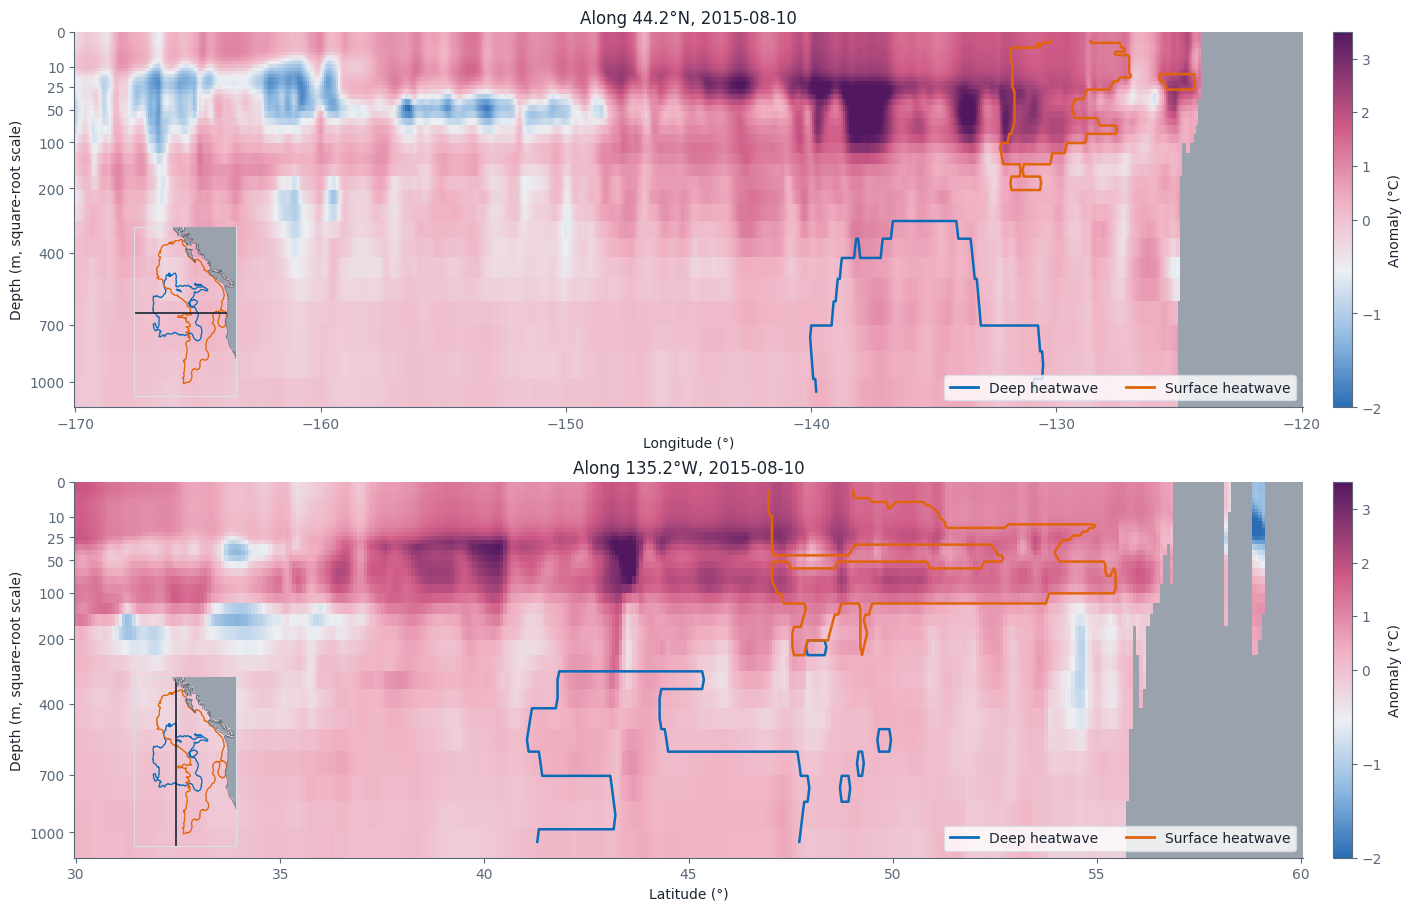

In [22]:
# Section 7: vertical sections through the deep heatwave's centroid on its peak day
main_lat = float(centroid.sel(component=0, ID=main_id, time=main_peak))
main_lon = float(centroid.sel(component=1, ID=main_id, time=main_peak))
anomaly_day = extremes_ds.dat_anomaly.sel(time=main_peak)
ids_day = events_ds.ID_field.sel(time=main_peak)
section_depth_edges = np.r_[level_top, level_bottom[-1]]

fig = plt.figure(figsize=(14, 9), layout="constrained")
axes = fig.subplots(2, 1)
sections = [
    (dict(lat=main_lat), "lon", f"Along {main_lat:.1f}°N", "Longitude (°)"),
    (dict(lon=main_lon), "lat", f"Along {abs(main_lon):.1f}°W", "Latitude (°)"),
]
for ax, (where, along, title, xlabel) in zip(axes, sections):
    anomaly_section = anomaly_day.sel(**where, method="nearest").compute()
    ids_section = ids_day.sel(**where, method="nearest").compute()
    coordinate = anomaly_section[along].values
    edges = np.r_[
        coordinate[0] - 0.5 * (coordinate[1] - coordinate[0]),
        0.5 * (coordinate[1:] + coordinate[:-1]),
        coordinate[-1] + 0.5 * (coordinate[-1] - coordinate[-2]),
    ]
    mesh = ax.pcolormesh(
        edges,
        section_depth_edges,
        anomaly_section.values,
        cmap=DIVERGING,
        norm=TwoSlopeNorm(0, vmin=-2, vmax=3.5),
        shading="flat",
        rasterized=True,
    )
    for event_id in (main_id, surface_id):
        ax.contour(
            coordinate,
            ids_section.depth,
            (ids_section == event_id).astype(int),
            levels=[0.5],
            colors=[COLOUR[event_id]],
            linewidths=1.8,
        )
    depth_axis(ax)
    ax.grid(False)
    ax.set_facecolor(LAND)
    ax.set(xlabel=xlabel, title=f"{title}, {main_peak:%Y-%m-%d}")
    fig.colorbar(mesh, ax=ax, label="Anomaly (°C)", pad=0.01)
    ax.legend(
        handles=[Line2D([], [], color=COLOUR[i], linewidth=2, label=NAME[i]) for i in (main_id, surface_id)],
        loc="lower right",
        ncol=2,
    )
    # A small map shows where the section runs
    locator = ax.inset_axes([0.015, 0.03, 0.15, 0.45])
    locator.patch.set_alpha(0.0)
    base_map(
        locator,
        mask.lon.values,
        mask.lat.values,
        extent=(render_box["lon"].start, render_box["lon"].stop, render_box["lat"].start, render_box["lat"].stop),
    )
    for event_id in (main_id, surface_id):
        locator.contour(
            mask.lon.values,
            mask.lat.values,
            (events_ds.ID_field.sel(time=main_peak) == event_id).any("depth").values.astype(float),
            levels=[0.5],
            colors=[COLOUR[event_id]],
            linewidths=0.9,
        )
    if along == "lon":
        locator.axhline(main_lat, color=INK, linewidth=1.2)
    else:
        locator.axvline(main_lon, color=INK, linewidth=1.2)
plt.show()

## 8. Tracks and Vertical Extent

On the left, the daily volume-weighted centroid of each event as a path. The line is thicker where the event is larger and
fades with age, and steps of more than 4° in a day are not joined. On the right, the depth range each event covers through
time, with the centroid as a line.

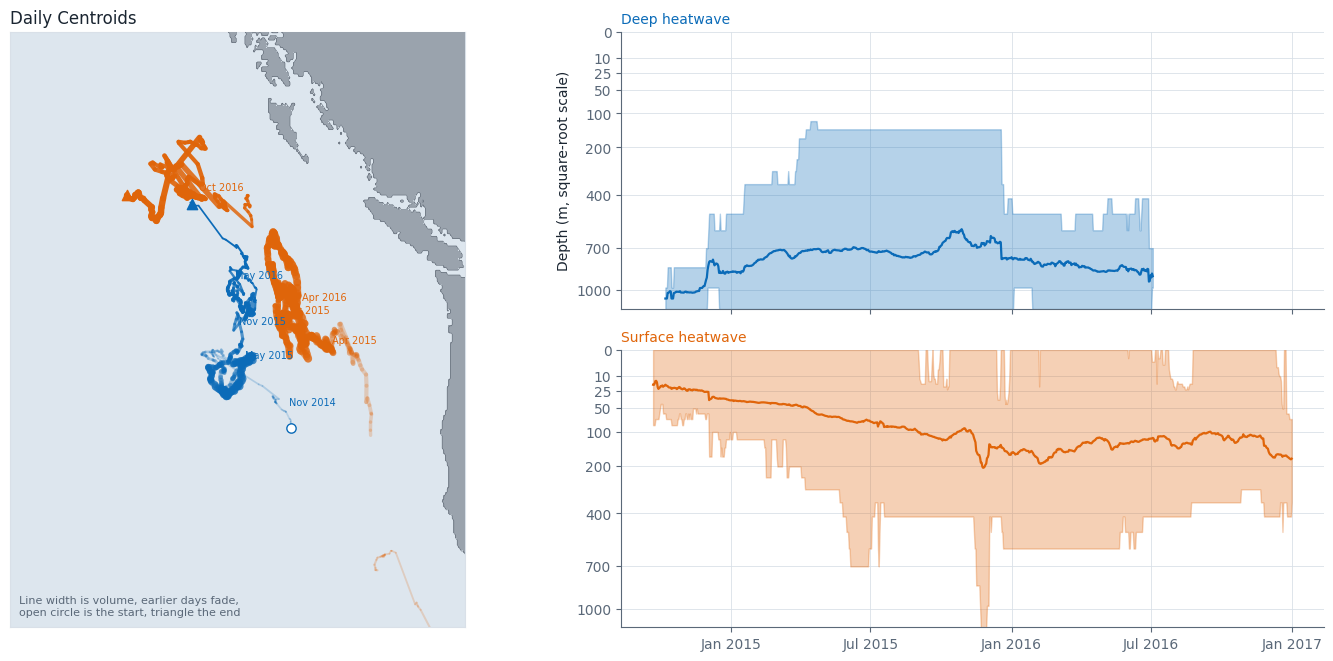

In [23]:
# Section 8: where each event's centre went, and the depth range it covered
fig = plt.figure(figsize=(14, 6.5), layout="constrained")
grid = fig.add_gridspec(2, 2, width_ratios=[1, 1.15])
ax_map = fig.add_subplot(grid[:, 0])
ax_depth = [fig.add_subplot(grid[0, 1]), None]
ax_depth[1] = fig.add_subplot(grid[1, 1], sharex=ax_depth[0], sharey=ax_depth[0])
lifetimes = {
    event_id: volume.sel(ID=event_id).dropna("time").where(lambda v: v > 0, drop=True) for event_id in (main_id, surface_id)
}
extent = field_extent(main_metrics.days_occupied > 0, pad=1.5)
base_map(ax_map, mask.lon.values, mask.lat.values, extent=(extent[0] - 2, extent[1] + 2, extent[2] - 2, extent[3] + 2))
for event_id in (main_id, surface_id):
    series = lifetimes[event_id]
    lon, lat = (centroid.sel(component=component, ID=event_id, time=series.time).values for component in (1, 0))
    points = np.c_[lon, lat]
    segments = np.stack([points[:-1], points[1:]], axis=1)
    fade = np.linspace(0.15, 1.0, len(segments))
    # A centroid can jump when an event gains or loses a distant part. Those steps are not drawn as a path.
    steps = np.diff(points, axis=0)
    jumps = np.hypot(steps[:, 0] * np.cos(np.deg2rad(lat[:-1])), steps[:, 1]) > 4.0
    colour = np.array(to_rgb(COLOUR[event_id]))
    ax_map.add_collection(
        LineCollection(
            segments[~jumps],
            colors=np.c_[np.tile(colour, (len(segments), 1)), fade][~jumps],
            linewidths=(1 + 5 * (series.values[1:] / series.max().item()))[~jumps],
            zorder=5,
            capstyle="round",
        )
    )
    ax_map.scatter(lon[0], lat[0], s=45, facecolors=FIGURE_BG, edgecolors=colour, zorder=6)
    ax_map.scatter(lon[-1], lat[-1], s=55, marker="^", color=colour, zorder=6)
    for month in pd.date_range(series.time.values[0], series.time.values[-1], freq="6MS"):
        k = int(np.abs(series.time.values - month.to_datetime64()).argmin())
        ax_map.annotate(
            f"{month:%b %Y}", (lon[k], lat[k]), xytext=(4, 4), textcoords="offset points", fontsize=7, color=colour, zorder=7
        )
    ax_depth_event = ax_depth[0 if event_id == main_id else 1]
    ax_depth_event.fill_between(
        series.time.values,
        depth_top.sel(ID=event_id, time=series.time),
        depth_bottom.sel(ID=event_id, time=series.time),
        color=colour,
        alpha=0.3,
    )
    ax_depth_event.plot(series.time.values, depth_centroid.sel(ID=event_id, time=series.time), color=colour, linewidth=1.6)
    ax_depth_event.set_title(NAME[event_id], color=COLOUR[event_id], fontsize=10, loc="left")
ax_map.set_title("Daily Centroids", loc="left")
ax_map.text(
    0.02,
    0.02,
    "Line width is volume, earlier days fade,\nopen circle is the start, triangle the end",
    transform=ax_map.transAxes,
    color=MUTED,
    fontsize=8,
    zorder=8,
)
depth_axis(ax_depth[0])
for ax in ax_depth:
    date_axis(ax)
ax_depth[0].tick_params(labelbottom=False)
ax_depth[1].set_ylabel("")
plt.show()

## 9. Mergers Shared with Other Events

Events that touch keep their own identities, and the tracker partitions the connected region between them, logging one row
in `merges_ds` for each merger. `parent_event_IDs` and `child_event_IDs` give the event of each parent and child object, so
the rows need no lookup. A merger's parents are objects of the day before `merge_time`.

The first figure follows the deep heatwave. Each lane is another event that was a parent in the same merger row. The thick bars
are runs of days on which the two were co-parents, and a line joins the lanes where each run starts. Two parents of one
merger need not touch each other, so a mark is not contact. The lanes are in the order the events first met the deep heatwave,
and the triangles are the deep heatwave's splits, the rows of `split_event_IDs`. A split is a piece of an object that overlaps its
continuation in two or more separate components of the retained objects' cells at that timestep. The second figure puts every
event at the time and depth of its peak, sized by volume, and joins the pairs that were co-parents on the most days.

The deep heatwave was a parent in 551 merger rows, with 83 other parent events on 551 days
Surface heatwave: 462 days as a co-parent
Splits of the deep heatwave: 13


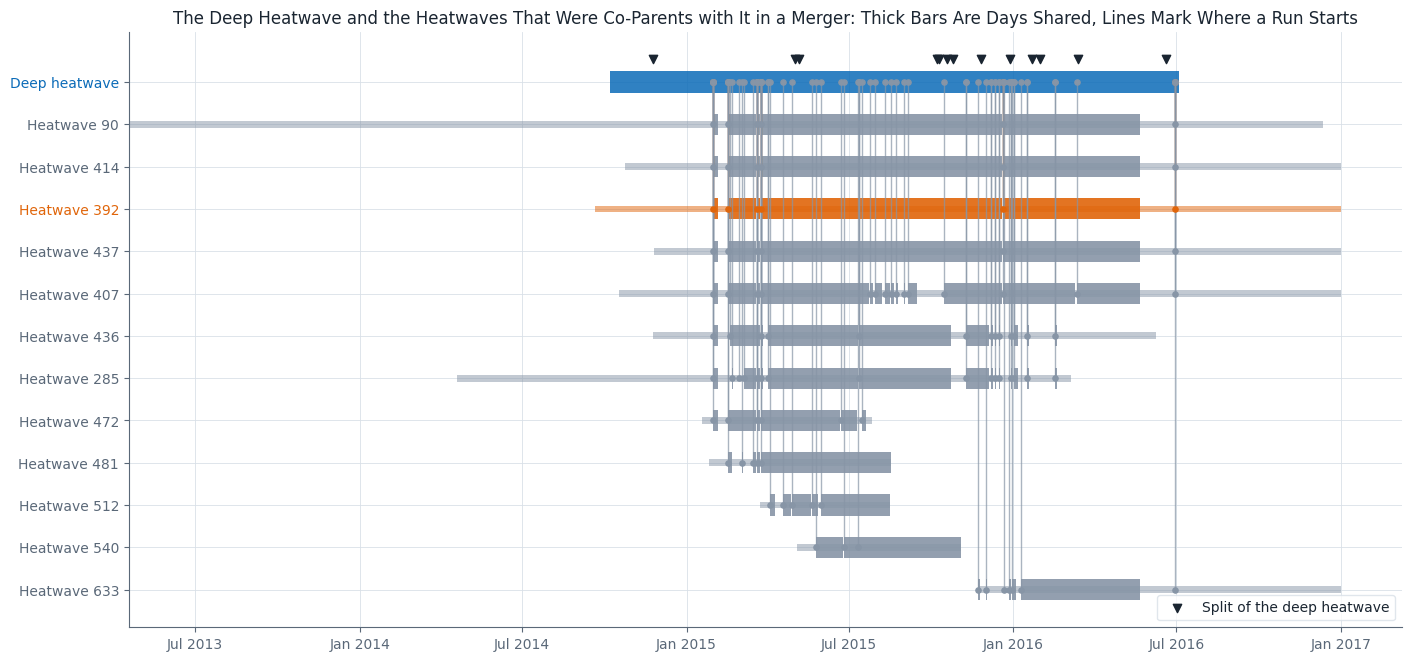

1591 pairs of events were co-parents, 150 on at least 74 days, joining 46 events


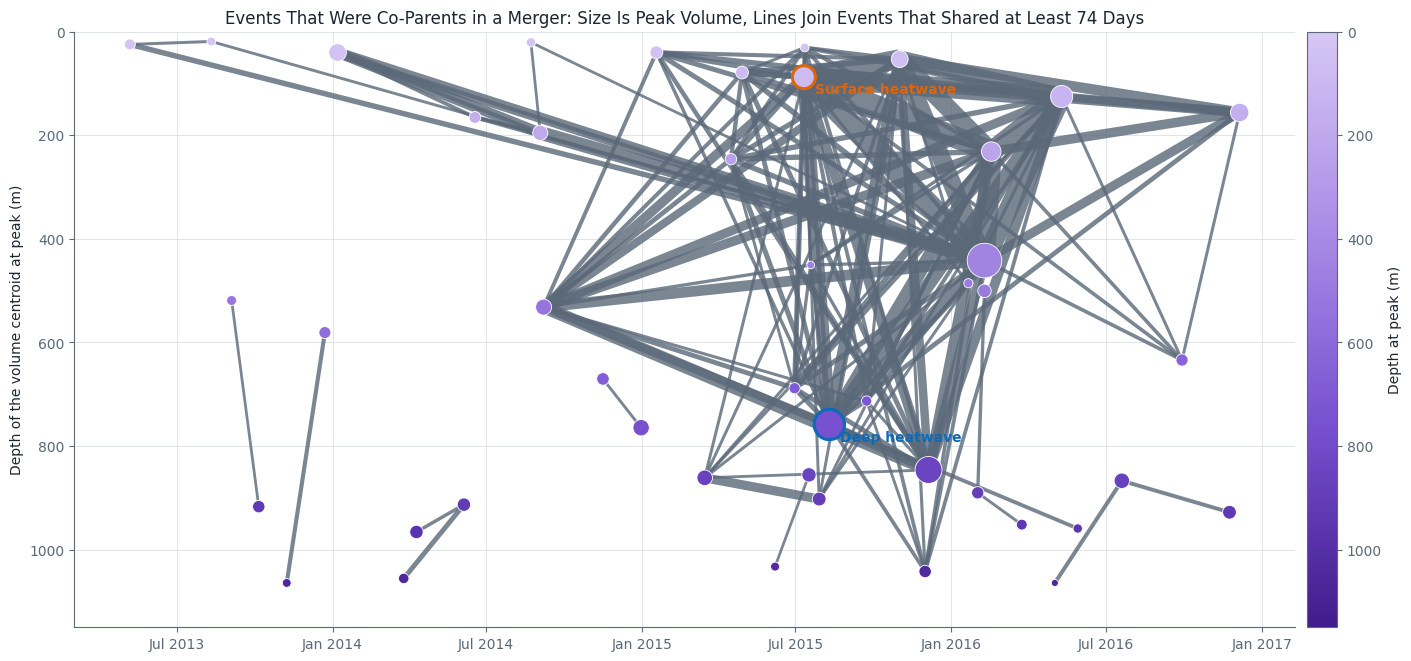

In [24]:
# Section 9: mergers and splits, from the event IDs the merge dataset records
parent_events = merges_ds.parent_event_IDs.values  # (merge_ID, parent_idx), -1 pads
merge_days = merges_ds.merge_time.values
split_days = merges_ds.split_time.values[merges_ds.split_event_IDs.values == main_id]

# Every merger row in which the deep heatwave was one of the parents, with the other parent events of that row
meetings = pd.DataFrame(
    [
        (day, partner)
        for day, row in zip(merge_days, parent_events)
        if main_id in row
        for partner in sorted(set(row[row > 0].tolist()) - {main_id})
    ],
    columns=["time", "ID"],
)
meeting_days = meetings.groupby("ID").time.nunique().sort_values(ascending=False)
print(
    f"The deep heatwave was a parent in {int((parent_events == main_id).any(axis=1).sum())} merger rows, with {meetings.ID.nunique()} other parent events on {meetings.time.nunique()} days"
)
print(f"{NAME[surface_id]}: {int(meeting_days.get(surface_id, 0))} days as a co-parent")
print(f"Splits of the deep heatwave: {len(split_days)}")

n_lanes = 12
lane_events = meeting_days.index[:n_lanes]
first_meeting = meetings.groupby("ID").time.min()
lane_events = sorted(lane_events, key=lambda partner: first_meeting[partner])  # ordered by first meeting


def runs_of_days(days):
    """First and last day of each run of consecutive days."""
    days = np.unique(days)
    return [(group[0], group[-1]) for group in np.split(days, np.flatnonzero(np.diff(days) > np.timedelta64(1, "D")) + 1)]


one_day = np.timedelta64(1, "D")
fig, ax = plt.subplots(figsize=(14, 6.5), layout="constrained")
ax.barh(
    0,
    (time_end.sel(ID=main_id) - time_start.sel(ID=main_id)).values + one_day,
    left=time_start.sel(ID=main_id).values,
    height=0.5,
    color=MAIN_COLOUR,
    alpha=0.85,
)
for lane, partner in enumerate(lane_events, start=1):
    colour = COLOUR.get(partner, OTHER_COLOUR)
    ax.barh(
        lane,
        (time_end.sel(ID=partner) - time_start.sel(ID=partner)).values + one_day,
        left=time_start.sel(ID=partner).values,
        height=0.16,
        color=colour,
        alpha=0.5,
    )
    for first, last in runs_of_days(meetings[meetings.ID == partner].time.values):
        ax.barh(
            lane, (last - first) + one_day, left=first, height=0.5, color=colour, alpha=0.9
        )  # the days both were parents of one merger
        ax.vlines(first, 0, lane, color=colour, alpha=0.7, linewidth=1.0)  # a connector where each run starts
        ax.scatter([first, first], [0, lane], s=14, color=colour, zorder=4)
if len(split_days):
    ax.scatter(
        split_days, np.full(split_days.size, -0.55), marker="v", s=36, color=INK, zorder=5, label="Split of the deep heatwave"
    )
    ax.legend(loc="lower right")
ax.set_yticks(range(len(lane_events) + 1), [NAME[main_id]] + [f"Heatwave {partner}" for partner in lane_events])
for tick, partner in zip(ax.get_yticklabels()[1:], lane_events):
    tick.set_color(COLOUR.get(partner, MUTED))
ax.get_yticklabels()[0].set_color(MAIN_COLOUR)
ax.invert_yaxis()
date_axis(ax)
ax.grid(True, axis="x")
ax.set_title(
    "The Deep Heatwave and the Heatwaves That Were Co-Parents with It in a Merger: Thick Bars Are Days Shared, Lines Mark Where a Run Starts"
)
plt.show()

# The population: events at their peak, joined by the days two events were parents of the same merger
shared = {}
for day, row in zip(merge_days, parent_events):
    present = sorted(set(row[row > 0].tolist()))
    for k, a in enumerate(present):
        for b in present[k + 1 :]:
            shared.setdefault((a, b), set()).add(day)
max_edges = 150  # the most lines the network draws: keep those joining events that shared the most days
by_weight = np.sort([len(days) for days in shared.values()])[::-1]
min_days = max(3, int(by_weight[min(max_edges, len(by_weight)) - 1]))
edges = {pair: len(days) for pair, days in shared.items() if len(days) >= min_days}
node_ids = sorted({event for pair in edges for event in pair} | {main_id, surface_id})
peak_day_of = volume.idxmax("time").sel(ID=node_ids).values
peak_depth_of = np.array([float(depth_centroid.sel(ID=event, time=day)) for event, day in zip(node_ids, peak_day_of)])
peak_volume_of = volume.max("time").sel(ID=node_ids).values
position = {event: (mdates.date2num(day), depth) for event, day, depth in zip(node_ids, peak_day_of, peak_depth_of)}
print(f"{len(shared)} pairs of events were co-parents, {len(edges)} on at least {min_days} days, joining {len(node_ids)} events")

fig, ax = plt.subplots(figsize=(14, 6.5), layout="constrained")
segments = [[position[a], position[b]] for (a, b) in edges]
weights = np.array(list(edges.values()))
ax.add_collection(
    LineCollection(segments, colors=[(*to_rgb(MUTED), min(0.8, 0.12 + 0.01 * w)) for w in weights], linewidths=0.5 + 0.02 * weights)
)
nodes = ax.scatter(
    *np.array([position[event] for event in node_ids]).T,
    s=20 + 600 * peak_volume_of / peak_volume_of.max(),
    c=peak_depth_of,
    cmap=DEPTH_CMAP,
    vmin=0,
    vmax=floor_depth,
    edgecolors=FIGURE_BG,
    linewidths=0.6,
    zorder=3,
)
for event_id in (main_id, surface_id):
    ax.scatter(
        *position[event_id],
        s=20 + 600 * float(volume.sel(ID=event_id).max()) / peak_volume_of.max(),
        facecolors="none",
        edgecolors=COLOUR[event_id],
        linewidths=2.2,
        zorder=4,
    )
    ax.annotate(
        NAME[event_id],
        position[event_id],
        xytext=(8, -12),
        textcoords="offset points",
        color=COLOUR[event_id],
        fontweight="bold",
        zorder=5,
    )
ax.set_ylim(floor_depth, 0)
ax.xaxis_date()
date_axis(ax)
ax.set(
    ylabel="Depth of the volume centroid at peak (m)",
    title=f"Events That Were Co-Parents in a Merger: Size Is Peak Volume, Lines Join Events That Shared at Least {min_days} Days",
)
fig.colorbar(nodes, ax=ax, label="Depth at peak (m)", pad=0.01).ax.invert_yaxis()
plt.show()

## 10. The `plotX` 4-D Helpers

The four helpers in `marEx.plotX` cover the standard views without any of the code above. Each selects the time steps,
levels or event it needs from the lazy `ID_field` before loading.

**Per-level maps.** All events at the deep heatwave's peak, on six levels. Other events are drawn in grey and the deep heatwave
in red, so it appears only on the levels it reaches. `zoom_to_event` frames the map on it.

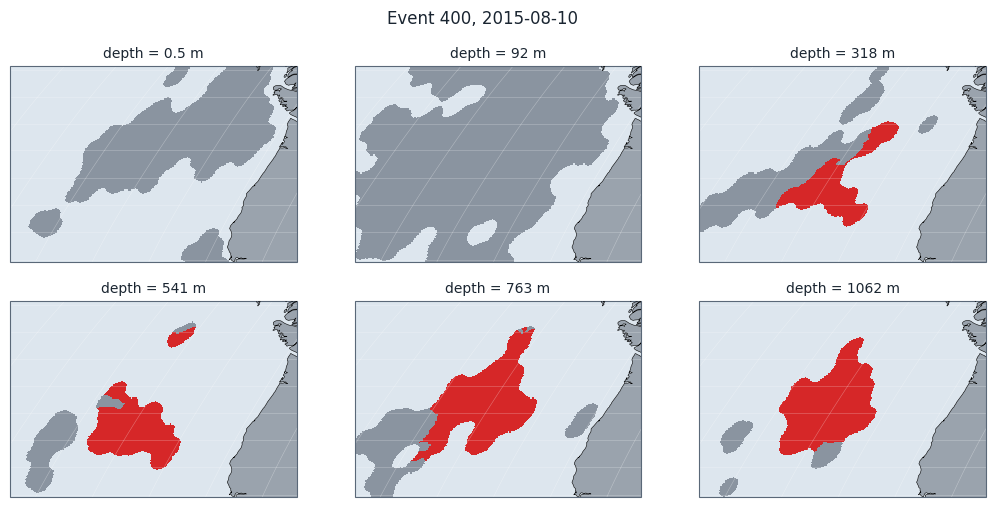

In [25]:
levels = [int(np.abs(events_ds.depth.values - depth).argmin()) for depth in (0, 100, 300, 500, 750, 1000)]
fig = plot_event_levels(events_ds, main_peak, levels, zdim="depth", event_id=main_id, zoom_to_event=True)

**Depth-time section.** The volume of the deep heatwave at each level through its life, on a square-root depth axis.

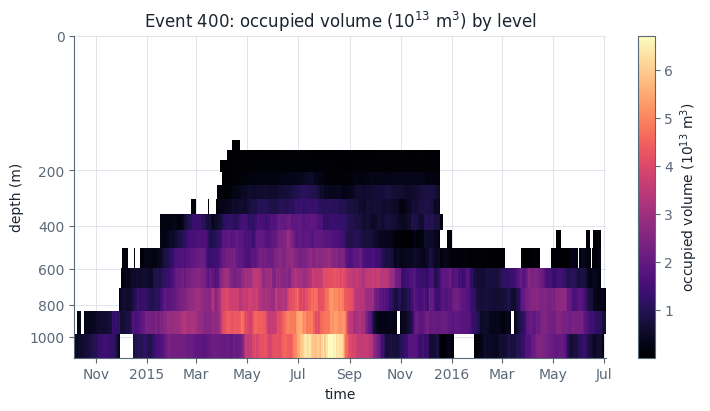

In [26]:
fig = plot_event_depth_time(
    events_ds, main_id, zdim="depth", quantity="volume", cell_volume=cell_volume.fillna(0.0), depth_scale="sqrt"
)

**Event summary.** The deep heatwave's volume, the depth of its centroid and its vertical extent. A dashed line
marks the first day of each unbroken run of days with a merger. A dotted line marks the same for splits, from `merges_ds`. The event merged on 551 of its 636 days, and the last run
lasts 467 days, from 2015-03-25 to the event's end.

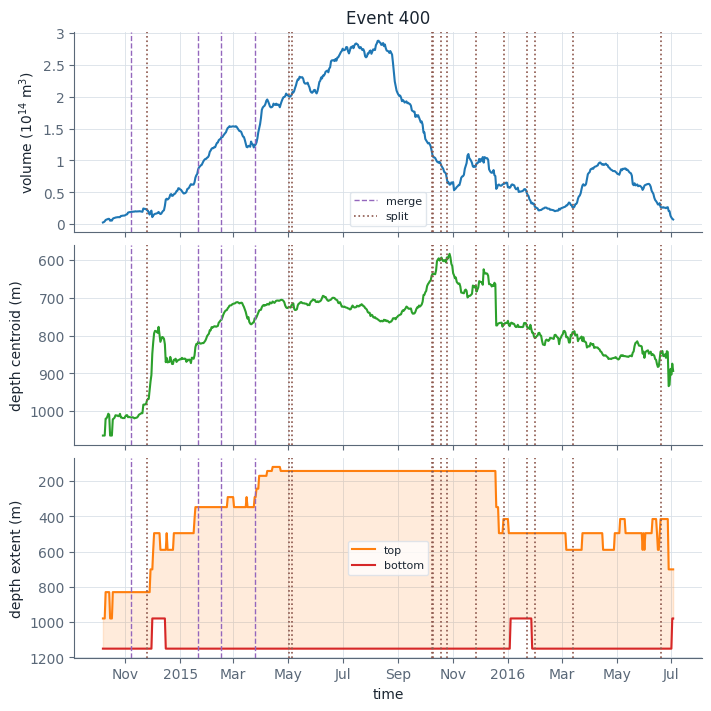

In [27]:
fig = plot_event_summary(events_ds, main_id, merges_ds)

## 11. Movies

**Events as isosurfaces.** Every third day of the deep heatwave's life, with a slow camera drift. Each frame has the scene, a small globe that locates the domain, and maps of the anomaly at the surface and at about 500 m, coloured only above the heatwave threshold, with the heatwaves outlined. A timeline marks the day on the excess heat and on the volume with no heatwave above it at the surface. Each frame is one dask task. `ffmpeg` encodes them at 8 frames per second, and the player shows
the copy in the repository's `media/` folder.

In [28]:
DEEP_NORM = HEAT_NORM


def map_panel(ax, field, threshold, ids, title):
    """Anomaly on one level of the box as a map, coloured only above the heatwave threshold. The heatwaves are outlined."""
    ax.imshow(
        heat_rgba(field, threshold),
        origin="lower",
        extent=[box_lon[0], box_lon[-1], box_lat[0], box_lat[-1]],
        aspect=1 / np.cos(np.deg2rad(box_lat.mean())),
        interpolation="nearest",
    )
    ax.contour(
        box_lon,
        box_lat,
        ((ids > 0) & ~np.isin(ids, [main_id, surface_id])).astype(float),
        levels=[0.5],
        colors=[NEUTRAL],
        linewidths=0.6,
    )
    for event_id in (main_id, surface_id):
        if (ids == event_id).any():
            ax.contour(box_lon, box_lat, (ids == event_id).astype(float), levels=[0.5], colors=[COLOUR[event_id]], linewidths=1.5)
    ax.set_title(title, fontsize=11, color=INK, loc="left")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


MOVIE_SCENE = [0.01, 0.24, 0.62, 0.62]  # the 3-D axes of the movie frame, in figure fractions
MAP_WIDTH, MAP_HEIGHT, MAP_BOTTOM = 0.152, 0.45, 0.365  # each map, in figure fractions: 0.6 wide for every 1 high on screen
MAP_LEFT = 0.91 - 2 * MAP_WIDTH - 0.006  # the right-hand map ends where the timelines end


def movie_frame(day, ids, anomaly, thr, norms, info, camera, path):
    """One composed 1920 x 1080 frame: the scene, two maps, and timelines with the day marked."""
    fig = plt.figure(figsize=(19.2, 10.8), dpi=100, facecolor=FIGURE_BG)
    ax = draw_scene(fig, MOVIE_SCENE, ids, anomaly, norms, thr[0], camera=camera, zoom=1.35)
    frame_text(fig, f"{day:%-d %B %Y}")
    for event_id, height in ((surface_id, 0.62), (main_id, 0.40)):
        if event_id in info:
            direct_label(
                ax, info[event_id]["anchor"], info[event_id]["name"], info[event_id]["detail"], (0.47, height), COLOUR[event_id]
            )
    for k, (level, title) in enumerate(((0, "Sea surface"), (DEEP_LEVEL, f"{box_depth[DEEP_LEVEL]:.0f} m down"))):
        ax_map = fig.add_axes([MAP_LEFT + (MAP_WIDTH + 0.006) * k, MAP_BOTTOM, MAP_WIDTH, MAP_HEIGHT])
        map_panel(ax_map, anomaly[level], thr[min(k, 1)], ids[level], title)
    heat_key(fig, MAP_LEFT, 0.295, 2 * MAP_WIDTH + 0.006)
    add_globe(fig)
    ax_heat = fig.add_axes([0.07, 0.135, 0.84, 0.055], facecolor="none")
    ax_hidden = fig.add_axes([0.07, 0.06, 0.84, 0.05], facecolor="none", sharex=ax_heat)
    timeline(ax_heat, day, film=True)
    ax_heat.tick_params(labelbottom=False)
    for series, colour in ((hidden_surface, SURFACE_COLOUR), (hidden_main, MAIN_COLOUR)):
        ax_hidden.plot(series.time.values, series.values / 1e15, color=colour, linewidth=1.6)
    ax_hidden.axvline(day, color=INK, linewidth=0.9)
    ax_hidden.text(
        0.005,
        0.95,
        "Heatwave volume with no heatwave above it at the surface (10¹⁵ m³)",
        transform=ax_hidden.transAxes,
        fontsize=9,
        color=MUTED,
        va="top",
    )
    ax_hidden.set_ylim(0, 1.3 * float(max(hidden_main.max(), hidden_surface.max())) / 1e15)
    ax_hidden.set_yticks([0, 0.2])
    ax_hidden.grid(False)
    ax_hidden.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
    ax_hidden.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    style_axes(ax_hidden)
    fig.savefig(path, dpi=100, facecolor=FIGURE_BG, pil_kwargs={"quality": 92} if str(path).endswith(".jpg") else {})
    plt.close(fig)

In [29]:
def render_frame(n, day, ids, anomaly, thr, info, frame_dir):
    plt.switch_backend("Agg")
    camera = (12, -48 + 14 * np.sin(2 * np.pi * n / 240))
    movie_frame(day, ids, anomaly, thr, movie_norms, info, camera, Path(frame_dir) / f"time_{n:04d}.jpg")


# The film is written for the README and the website, so it is drawn in the dark look; the other figures of this notebook stay light
page_look = set_look("dark")
movie_norms = ramps(ids_peak, anomaly_peak)
movie_days = pd.date_range(start, end, freq=f"{movie_every}D")
frame_dir = plot_dir / "frames_movie_events_4d"
frame_dir.mkdir(exist_ok=True)
ids_box = events_ds.ID_field.sel(time=movie_days, **render_box)
anomaly_box = extremes_ds.dat_anomaly.sel(time=movie_days, **render_box)
frames = [
    dask.delayed(render_frame)(
        n, day, ids_box.isel(time=n).data, anomaly_box.isel(time=n).data, threshold_slices(day), frame_info(day), str(frame_dir)
    )
    for n, day in enumerate(movie_days)
]
with monitor.stage("Movie: events as isosurfaces"):
    dask.compute(*frames)
    movie_events = plot_dir / "movie_events_4d.mp4"
    if shutil.which("ffmpeg"):
        subprocess.run(
            ["ffmpeg", "-hide_banner", "-loglevel", "error", "-y", "-framerate", "8", "-i", str(frame_dir / "time_%04d.jpg")]
            + [
                "-c:v",
                "libx264",
                "-preset",
                "slow",
                "-crf",
                "22",
                "-pix_fmt",
                "yuv420p",
                "-movflags",
                "+faststart",
                str(movie_events),
            ],
            check=True,
        )
    shutil.rmtree(frame_dir)
set_look(page_look)
print(f"{len(movie_days)} frames, {movie_events if movie_events.exists() else 'no movie: ffmpeg is not installed'}")
Video(url="../../media/movie_events_4d.mp4", width=960, height=540)

<env>/lib/python3.10/site-packages/distributed/client.py:3370: UserWarning: Sending large graph of size 141.39 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Movie: events as isosurfaces: 4.0 min, peak worker memory 22.9 GB of 224 GB (largest worker 2.6 of 14.0 GB), client 3.1 GB, spilled 0.0 GB, restarts 0
212 frames, /scratch/<u>/<user>/marEx/examples/4d/plots/movie_events_4d.mp4


**Footprint of all events.** `animate_event_levels` projects every event onto the map and colours it by the depth of the
shallowest level it reaches, here for the 181 days around the deep heatwave's peak and zoomed to the box of the 3-D figures. A movie
needs `ffmpeg`, and without it the helper returns `None`.

In [30]:
movie_window = slice(main_peak - pd.Timedelta(days=90), main_peak + pd.Timedelta(days=90))
page_look = set_look("dark")  # a film for the README and the website, as above
with monitor.stage("Movie: event footprint depth"):
    movie = animate_event_levels(
        events_ds.sel(time=movie_window),
        zdim="depth",
        levels="footprint",
        plot_dir=plot_dir,
        file_name="movie_event_footprint_4d",
        config=PlotConfig(cmap=FOOTPRINT_CMAP, grid_lines=False),
        theme="dark",
        extent=(
            render_box["lon"].start,
            render_box["lon"].stop,
            render_box["lat"].start,
            render_box["lat"].stop,
        ),  # the box of the 3-D figures
    )
set_look(page_look)
print(f"movie written to {movie}" if movie else "no movie: ffmpeg is not installed on this machine")
Video(url="../../media/movie_event_footprint_4d.mp4", width=640, height=480)

Movie: event footprint depth: 5.5 min, peak worker memory 17.3 GB of 224 GB (largest worker 1.2 of 14.0 GB), client 2.9 GB, spilled 0.0 GB, restarts 0
movie written to /scratch/<u>/<user>/marEx/examples/4d/plots/movie_event_footprint_4d.mp4


## Wall Time and Memory

Peak memory summed over workers, the largest single worker, and the client (this kernel), per stage.

In [31]:
monitor.summary()

,wall (min),peak worker memory (GB),peak per worker (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,,
Analysis: event metrics,1.06,76.49,8.32,0.89,0.0,0
Heatwave thresholds,0.02,7.64,0.67,1.18,0.0,0
Isosurfaces: the peak,0.89,7.08,0.49,1.82,0.0,0
Isosurfaces: life cycle,1.85,8.36,0.81,2.52,0.0,0
Movie: events as isosurfaces,4.03,22.86,2.60,3.12,0.0,0
Movie: event footprint depth,5.47,17.29,1.17,2.91,0.0,0
total,13.33,76.49,8.32,3.12,0.0,0


In [32]:
client.close()